
# HealthSync — Clusterização de Perfis Cardiometabólicos

## 1. Análise Exploratória dos Dados

Este estudo utiliza dados do National Health and Nutrition
Examination Survey (NHANES), ciclo 2021–2023, para identificar
subperfis cardiometabólicos por meio do algoritmo K-Means.

A amostra analisada contém 5.202 participantes com dados
completos para as variáveis selecionadas.

Os participantes foram divididos em três estratos de HbA1c:

- Estrato 1: HbA1c < 5,7%
- Estrato 2: 5,7% ≤ HbA1c < 6,5%
- Estrato 3: HbA1c ≥ 6,5%

A clusterização foi realizada separadamente em cada estrato,
utilizando cinco variáveis:

- Idade
- Índice de Massa Corporal (IMC)
- Pressão arterial sistólica
- Pressão arterial diastólica
- Colesterol total

**Objetivo:** identificar e caracterizar padrões descritivos
de características cardiometabólicas dentro de cada estrato.

Os agrupamentos não representam diagnósticos clínicos nem
estimativas validadas de risco cardiovascular.


In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid", context="notebook")

arquivo = Path("healthsync_perfis_cardiometabolicos.csv")

if not arquivo.exists():
    raise FileNotFoundError(
        f"CSV não encontrado em: {Path.cwd()}"
    )

df = pd.read_csv(arquivo)

features = [
    "idade",
    "imc",
    "pressao_sistolica",
    "pressao_diastolica",
    "colesterol_total"
]

print("Dimensões:", df.shape)
print("Participantes:", len(df))
print("Valores ausentes nas variáveis selecionadas:")
print(df[features].isna().sum())

display(df.head())


Dimensões: (5202, 13)
Participantes: 5202
Valores ausentes nas variáveis selecionadas:
idade                 0
imc                   0
pressao_sistolica     0
pressao_diastolica    0
colesterol_total      0
dtype: int64


,estrato_glicemico,idade,imc,pressao_sistolica,pressao_diastolica,colesterol_total,atv_moderada_min_semana,atv_vigorosa_min_semana,minutos_sedentarios_dia,cluster,estrato_hba1c,atividade_vigorosa_binaria,perfil_id
0,HbA1c < 5.7,43.0,27.0,132.7,96.0,264.0,135.0,135.0,360.0,1,HbA1c < 5.7,NaN,E1_C1
1,HbA1c < 5.7,66.0,33.5,117.0,78.7,214.0,180.0,135.0,480.0,1,HbA1c < 5.7,NaN,E1_C1
2,HbA1c < 5.7,34.0,30.2,115.0,73.7,183.0,30.0,6.9,180.0,0,HbA1c < 5.7,NaN,E1_C0
3,HbA1c < 5.7,33.0,38.9,106.0,72.7,157.0,210.0,140.0,240.0,0,HbA1c < 5.7,NaN,E1_C0
4,HbA1c < 5.7,74.0,43.0,158.3,71.3,191.0,0.0,0.0,300.0,1,HbA1c < 5.7,NaN,E1_C1


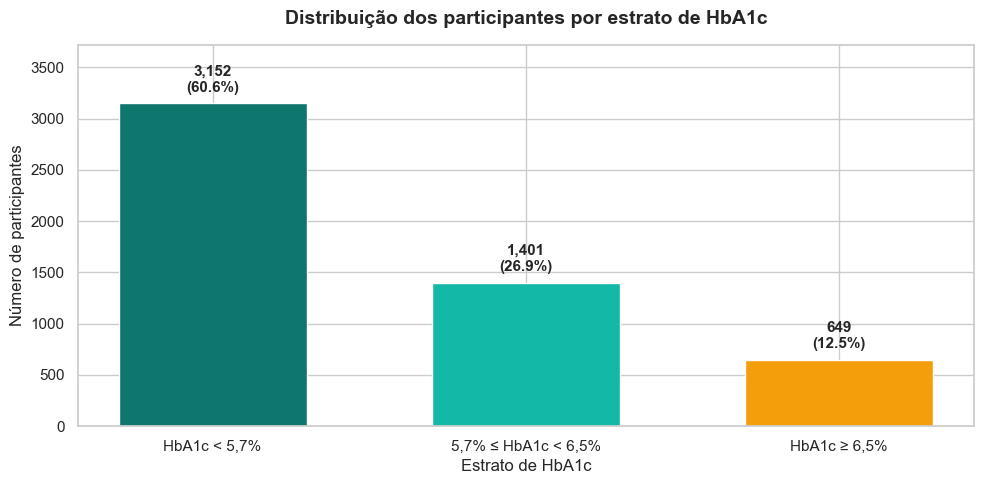

In [4]:

ordem_estratos = [
    "HbA1c < 5.7",
    "5.7 <= HbA1c < 6.5",
    "HbA1c >= 6.5"
]

contagem = (
    df["estrato_hba1c"]
    .value_counts()
    .reindex(ordem_estratos)
)

rotulos = [
    "HbA1c < 5,7%",
    "5,7% ≤ HbA1c < 6,5%",
    "HbA1c ≥ 6,5%"
]

fig, ax = plt.subplots(figsize=(10, 5))

cores = ["#0E766D", "#14B8A6", "#F59E0B"]

barras = ax.bar(
    rotulos,
    contagem.values,
    color=cores,
    width=0.6
)

for barra, quantidade in zip(barras, contagem.values):
    percentual = quantidade / len(df) * 100

    ax.annotate(
        f"{quantidade:,}\n({percentual:.1f}%)",
        xy=(barra.get_x() + barra.get_width() / 2,
            barra.get_height()),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

ax.set_title(
    "Distribuição dos participantes por estrato de HbA1c",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Estrato de HbA1c")
ax.set_ylabel("Número de participantes")
ax.set_ylim(0, contagem.max() * 1.18)

plt.tight_layout()
plt.show()


### Interpretação

A amostra analítica é composta por 5.202 participantes,
distribuídos em três estratos de HbA1c.

O primeiro estrato concentra 3.152 participantes (60,6%),
seguido pelo segundo estrato, com 1.401 (26,9%), e pelo
terceiro estrato, com 649 (12,5%).

Essa distribuição evidencia diferenças no tamanho amostral
entre os estratos, aspecto relevante para a interpretação
das análises de clusterização realizadas separadamente.

Os percentuais descrevem apenas a amostra selecionada,
não devendo ser interpretados como estimativas de
prevalência na população.



## 1.2. Análise de Correlação das Variáveis

A análise de correlação tem como objetivo investigar as
associações entre as cinco variáveis utilizadas na clusterização.

Foi utilizado o coeficiente de Spearman, que avalia a
intensidade e a direção de associações monotônicas.

Essa análise é exploratória e não estabelece relações
de causalidade entre as variáveis.


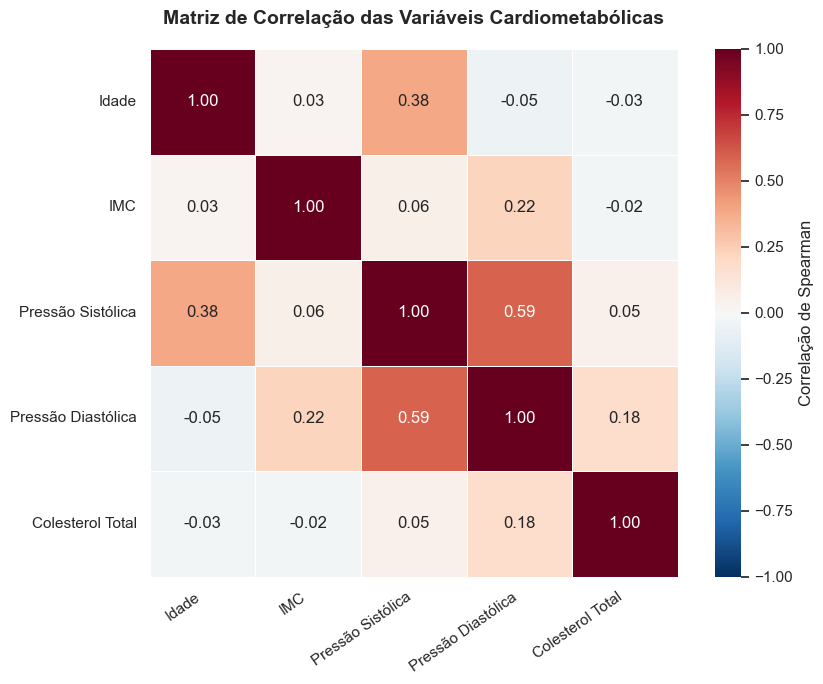

In [5]:

# Variáveis utilizadas no K-Means
features = [
    "idade",
    "imc",
    "pressao_sistolica",
    "pressao_diastolica",
    "colesterol_total"
]

nomes_variaveis = {
    "idade": "Idade",
    "imc": "IMC",
    "pressao_sistolica": "Pressão Sistólica",
    "pressao_diastolica": "Pressão Diastólica",
    "colesterol_total": "Colesterol Total"
}

# Calcular correlação de Spearman
matriz_corr = df[features].corr(method="spearman")

# Renomear para melhorar a visualização
matriz_corr = matriz_corr.rename(
    index=nomes_variaveis,
    columns=nomes_variaveis
)

# Criar heatmap
plt.figure(figsize=(9, 7))

sns.heatmap(
    matriz_corr,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Correlação de Spearman"}
)

plt.title(
    "Matriz de Correlação das Variáveis Cardiometabólicas",
    fontsize=14,
    fontweight="bold",
    pad=18
)

plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()



### Interpretação da Matriz de Correlação

A análise de correlação de Spearman identificou diferentes
intensidades de associação entre as variáveis cardiometabólicas.

A maior correlação observada ocorreu entre pressão arterial
sistólica e diastólica (ρ = 0,587), indicando uma associação
positiva moderada entre essas medidas.

A idade apresentou associação positiva com a pressão
sistólica (ρ = 0,383), enquanto o IMC apresentou associação
positiva fraca com a pressão diastólica (ρ = 0,224).

O colesterol total apresentou correlações de baixa magnitude
com as demais variáveis, sugerindo que sua distribuição não
acompanha fortemente as variações monotônicas dos outros
indicadores na amostra analisada.

Esses resultados contribuem para a caracterização exploratória
das variáveis utilizadas na clusterização. Entretanto, a
matriz representa a amostra completa, e as associações
podem diferir dentro dos estratos de HbA1c.

As correlações observadas não implicam relações causais.


In [6]:

from itertools import combinations

corr = df[features].corr(method="spearman")

pares = []

for var1, var2 in combinations(features, 2):
    pares.append({
        "Variável 1": nomes_variaveis[var1],
        "Variável 2": nomes_variaveis[var2],
        "Correlação": corr.loc[var1, var2]
    })

tabela_corr = pd.DataFrame(pares)

tabela_corr = tabela_corr.sort_values(
    "Correlação",
    key=lambda x: x.abs(),
    ascending=False
)

display(tabela_corr.round(3))



,Variável 1,Variável 2,Correlação
7,Pressão Sistólica,Pressão Diastólica,0.587
1,Idade,Pressão Sistólica,0.383
5,IMC,Pressão Diastólica,0.224
9,Pressão Diastólica,Colesterol Total,0.180
4,IMC,Pressão Sistólica,0.061
8,Pressão Sistólica,Colesterol Total,0.050
2,Idade,Pressão Diastólica,-0.050
3,Idade,Colesterol Total,-0.030
0,Idade,IMC,0.027
6,IMC,Colesterol Total,-0.025



## 1.3. Distribuição das Variáveis Cardiometabólicas

Nesta etapa, são analisadas as distribuições das cinco
variáveis selecionadas para a clusterização.

Os histogramas permitem observar a concentração dos valores,
a dispersão e possíveis assimetrias na amostra.

A análise contribui para compreender as características
dos dados antes da aplicação do algoritmo K-Means.


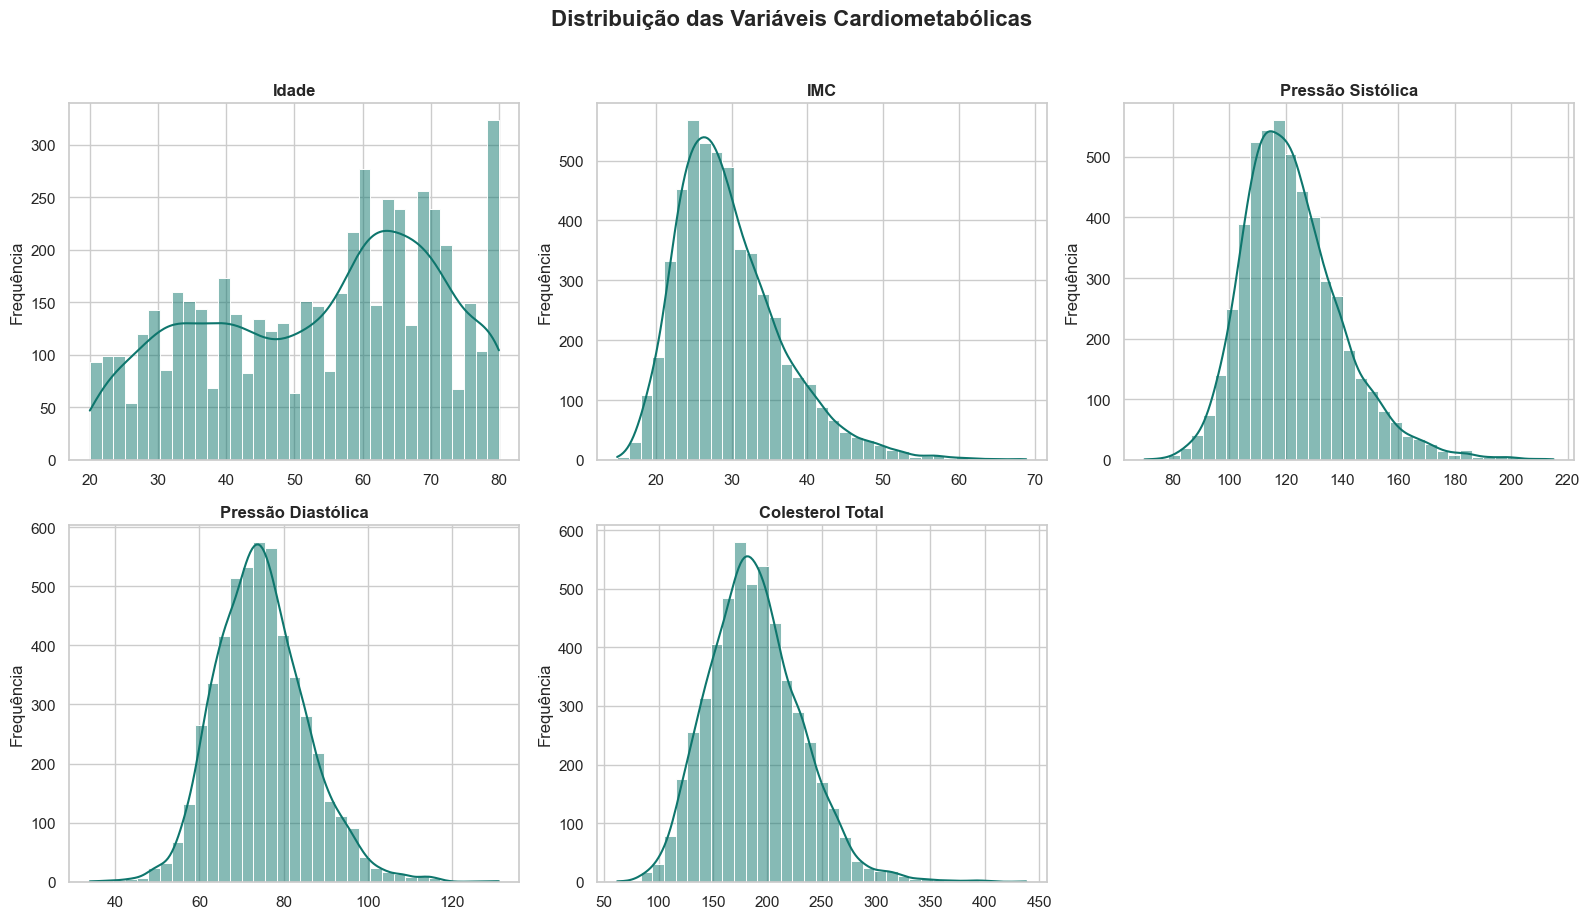

In [7]:

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

axes = axes.flatten()

for i, feature in enumerate(features):
    sns.histplot(
        data=df,
        x=feature,
        bins=35,
        kde=True,
        color="#0E766D",
        ax=axes[i]
    )

    axes[i].set_title(
        nomes_variaveis[feature],
        fontsize=12,
        fontweight="bold"
    )

    axes[i].set_xlabel("")
    axes[i].set_ylabel("Frequência")

# Remover o sexto gráfico vazio
fig.delaxes(axes[-1])

fig.suptitle(
    "Distribuição das Variáveis Cardiometabólicas",
    fontsize=16,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()



### Interpretação das Distribuições

A análise dos histogramas revelou diferenças nos padrões de
distribuição das cinco variáveis cardiometabólicas.

A idade apresentou uma distribuição heterogênea, com maior
concentração de participantes em faixas etárias mais avançadas.

O IMC apresentou assimetria positiva acentuada, com concentração
de observações em valores mais baixos e uma cauda prolongada
em direção aos valores elevados.

A pressão arterial sistólica apresentou distribuição unimodal,
com leve assimetria positiva, enquanto a pressão diastólica
apresentou maior concentração em torno de sua região central.

O colesterol total também apresentou distribuição unimodal,
com assimetria positiva e presença de valores elevados.

Essas características reforçam a importância do pré-processamento
das variáveis antes da aplicação do K-Means.

Neste estudo, foi utilizado o RobustScaler, que realiza a
transformação com base na mediana e no intervalo interquartil,
reduzindo a influência de valores extremos sobre a escala
das variáveis.

Entretanto, essa transformação não elimina valores extremos
nem garante que eles deixem de influenciar os agrupamentos.



## 1.4. Análise de Dispersão e Valores Extremos

Os boxplots permitem visualizar a mediana, o intervalo
interquartil e possíveis valores extremos das variáveis.

Essa análise complementa os histogramas e contribui para
compreender a dispersão dos dados antes da clusterização.


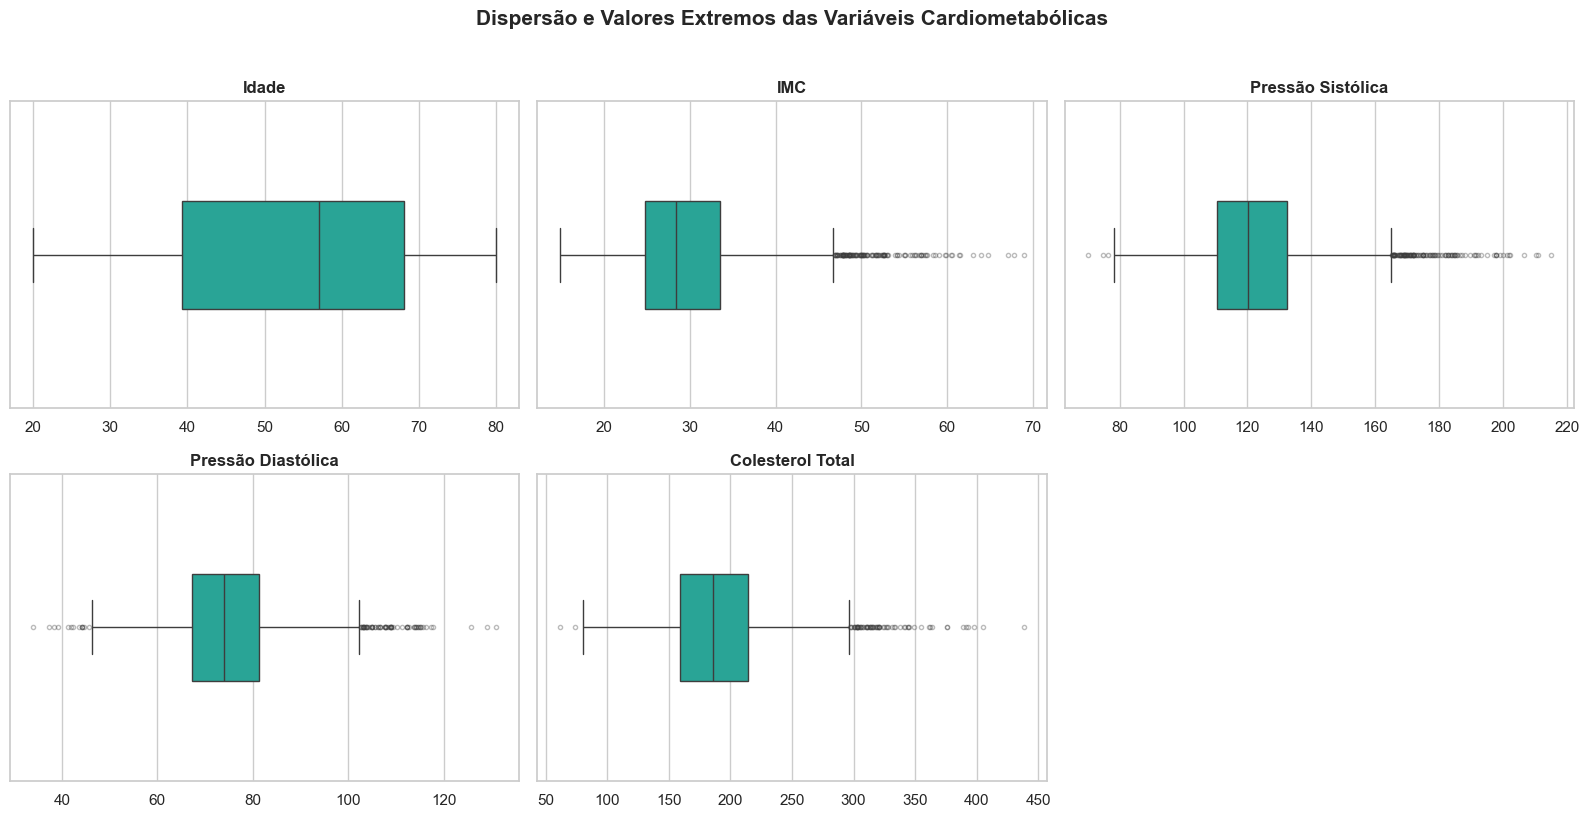

In [8]:

fig, axes = plt.subplots(2, 3, figsize=(16, 8))

axes = axes.flatten()

for i, feature in enumerate(features):
    sns.boxplot(
        data=df,
        x=feature,
        color="#14B8A6",
        ax=axes[i],
        width=0.35,
        flierprops={
            "marker": "o",
            "markersize": 3,
            "alpha": 0.35
        }
    )

    axes[i].set_title(
        nomes_variaveis[feature],
        fontsize=12,
        fontweight="bold"
    )

    axes[i].set_xlabel("")
    axes[i].set_ylabel("")

fig.delaxes(axes[-1])

fig.suptitle(
    "Dispersão e Valores Extremos das Variáveis Cardiometabólicas",
    fontsize=15,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()



### Interpretação dos Boxplots

A análise dos boxplots evidenciou diferenças na dispersão
das variáveis cardiometabólicas e na ocorrência de
observações estatisticamente extremas.

A idade apresentou ampla variabilidade, sem observações
identificadas como outliers pelo critério de 1,5 vez
o intervalo interquartil (IQR).

O IMC apresentou diversos valores extremos superiores,
reforçando a assimetria positiva identificada nos histogramas.

As pressões arteriais sistólica e diastólica também
apresentaram observações extremas, enquanto o colesterol
total exibiu valores elevados afastados da distribuição central.

Esses resultados contribuíram para a escolha do RobustScaler
no pré-processamento, considerando sua menor sensibilidade
a valores extremos em comparação com métodos baseados
na média e no desvio-padrão.

Entretanto, a transformação não elimina os outliers nem
impede completamente sua influência sobre o K-Means.



# 2. Metodologia da Clusterização

## 2.1. Estratégia de Agrupamento

A clusterização foi realizada utilizando o algoritmo K-Means,
com o objetivo de identificar subperfis cardiometabólicos
dentro de três estratos de hemoglobina glicada (HbA1c).

Os participantes foram previamente divididos em:

- Estrato 1: HbA1c < 5,7%
- Estrato 2: 5,7% ≤ HbA1c < 6,5%
- Estrato 3: HbA1c ≥ 6,5%

O K-Means foi aplicado separadamente em cada estrato,
utilizando cinco variáveis:

1. Idade
2. Índice de Massa Corporal (IMC)
3. Pressão arterial sistólica
4. Pressão arterial diastólica
5. Colesterol total

A HbA1c foi utilizada exclusivamente para a estratificação
dos participantes, não participando diretamente do cálculo
das distâncias do K-Means.

## 2.2. Pré-processamento

Foi aplicado o RobustScaler separadamente em cada estrato.

Essa transformação centraliza os valores utilizando a mediana
e ajusta a escala pelo intervalo interquartil, reduzindo a
sensibilidade do pré-processamento a observações extremas.

## 2.3. Escolha do Número de Clusters

Foram avaliados diferentes valores de K, considerando
principalmente o Silhouette Score e a estabilidade dos
agrupamentos obtidos.

Os valores selecionados foram:

- Estrato 1: K = 2
- Estrato 2: K = 6
- Estrato 3: K = 2

A escolha de K = 6 no Estrato 2 também considerou a maior
estabilidade observada em relação à alternativa K = 2,
apesar de seus Silhouette Scores serem muito próximos.



## 2.4. Avaliação do Número de Clusters

Para avaliar diferentes números de agrupamentos, foram
calculadas duas métricas:

- **Inércia (Elbow):** soma das distâncias quadráticas dos
  participantes aos centroides de seus respectivos clusters.
- **Silhouette Score:** avalia a coesão interna e a separação
  entre os agrupamentos.

Foram avaliados valores de K entre 2 e 10, separadamente
para cada estrato de HbA1c.

A seleção final também considerou a estabilidade dos
agrupamentos obtidos por reamostragem.


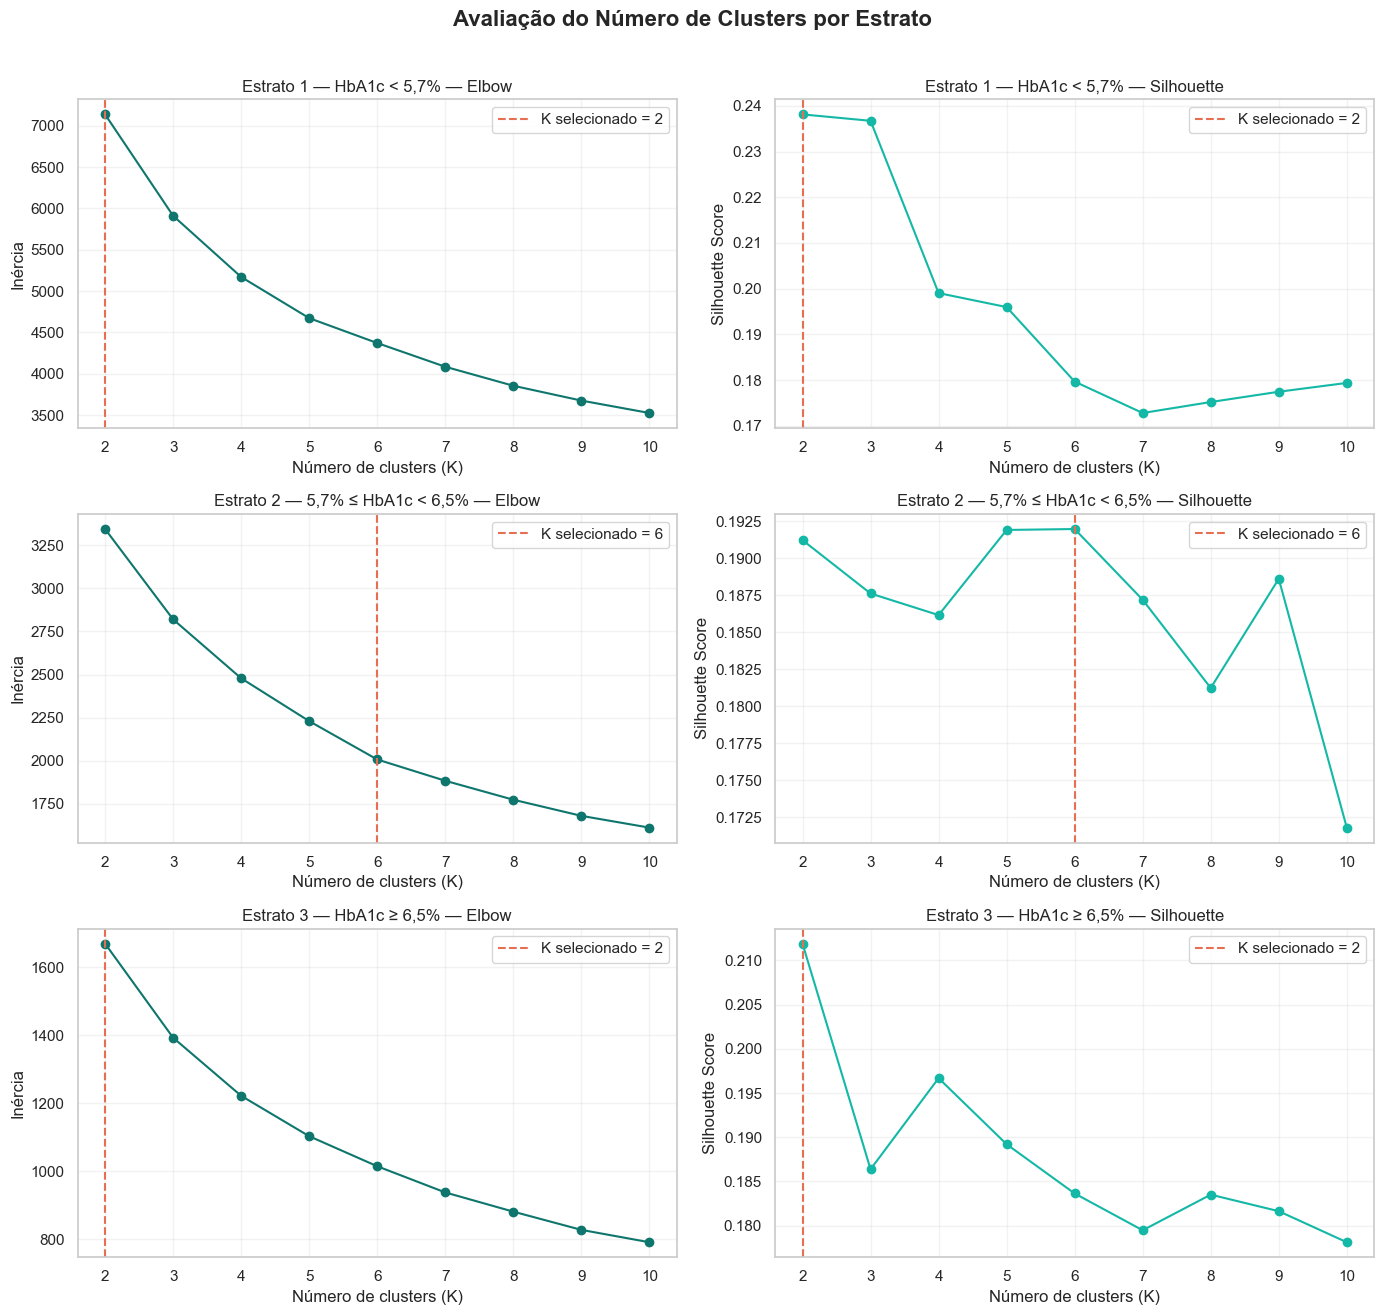

In [9]:

import pandas as pd
import matplotlib.pyplot as plt

metricas_k = pd.read_csv("metricas_kmeans_por_estrato.csv")

nomes_estratos = {
    "E1": "Estrato 1 — HbA1c < 5,7%",
    "E2": "Estrato 2 — 5,7% ≤ HbA1c < 6,5%",
    "E3": "Estrato 3 — HbA1c ≥ 6,5%"
}

k_selecionados = {
    "E1": 2,
    "E2": 6,
    "E3": 2
}

fig, axes = plt.subplots(3, 2, figsize=(14, 13))

for i, estrato in enumerate(["E1", "E2", "E3"]):
    dados = metricas_k[
        metricas_k["estrato"] == estrato
    ].sort_values("k")

    k_final = k_selecionados[estrato]

    # Elbow
    axes[i, 0].plot(
        dados["k"],
        dados["inercia"],
        marker="o",
        color="#0E766D"
    )

    axes[i, 0].axvline(
        k_final,
        color="#E76F51",
        linestyle="--",
        label=f"K selecionado = {k_final}"
    )

    axes[i, 0].set_title(
        f"{nomes_estratos[estrato]} — Elbow"
    )
    axes[i, 0].set_xlabel("Número de clusters (K)")
    axes[i, 0].set_ylabel("Inércia")
    axes[i, 0].legend()

    # Silhouette
    axes[i, 1].plot(
        dados["k"],
        dados["silhouette"],
        marker="o",
        color="#14B8A6"
    )

    axes[i, 1].axvline(
        k_final,
        color="#E76F51",
        linestyle="--",
        label=f"K selecionado = {k_final}"
    )

    axes[i, 1].set_title(
        f"{nomes_estratos[estrato]} — Silhouette"
    )
    axes[i, 1].set_xlabel("Número de clusters (K)")
    axes[i, 1].set_ylabel("Silhouette Score")
    axes[i, 1].legend()

    for ax in axes[i]:
        ax.set_xticks(dados["k"])
        ax.grid(alpha=0.25)

fig.suptitle(
    "Avaliação do Número de Clusters por Estrato",
    fontsize=16,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.show()



### Interpretação da Escolha do Número de Clusters

A avaliação do número de clusters foi realizada separadamente
para os três estratos de HbA1c, considerando valores de K
entre 2 e 10.

No Estrato 1, o maior Silhouette Score foi observado em K = 2
(0,2382), sendo essa a configuração selecionada.

No Estrato 2, os resultados de Silhouette foram próximos
entre diferentes configurações, com destaque para K = 5
e K = 6. A configuração K = 6 apresentou Silhouette Score
de 0,1920 e foi selecionada considerando também a
estabilidade dos agrupamentos por reamostragem e sua
capacidade de representar diferentes padrões descritivos.

No Estrato 3, K = 2 apresentou o maior Silhouette Score
(0,2119), justificando sua seleção.

Em todos os estratos, a inércia diminuiu progressivamente
com o aumento de K, sem apresentar um ponto de cotovelo
inequívoco. Dessa forma, o método Elbow foi utilizado
como análise complementar, e não como critério isolado.

Os valores relativamente baixos de Silhouette indicam
sobreposição entre os agrupamentos, uma limitação
importante para a interpretação dos perfis.

Assim, os clusters encontrados são tratados como
subperfis cardiometabólicos exploratórios, sem
atribuição de significado diagnóstico ou prognóstico.



## 2.5. Análise Individual dos Coeficientes de Silhouette

Além da avaliação do Silhouette Score médio, foi analisada
a distribuição dos coeficientes individuais de silhouette
dos participantes em cada cluster.

Valores próximos de 1 indicam maior separação em relação
aos demais agrupamentos, enquanto valores próximos de zero
indicam observações próximas às fronteiras entre clusters.

Valores negativos indicam que, segundo essa métrica,
a observação está mais próxima de outro agrupamento
do que daquele ao qual foi atribuída.


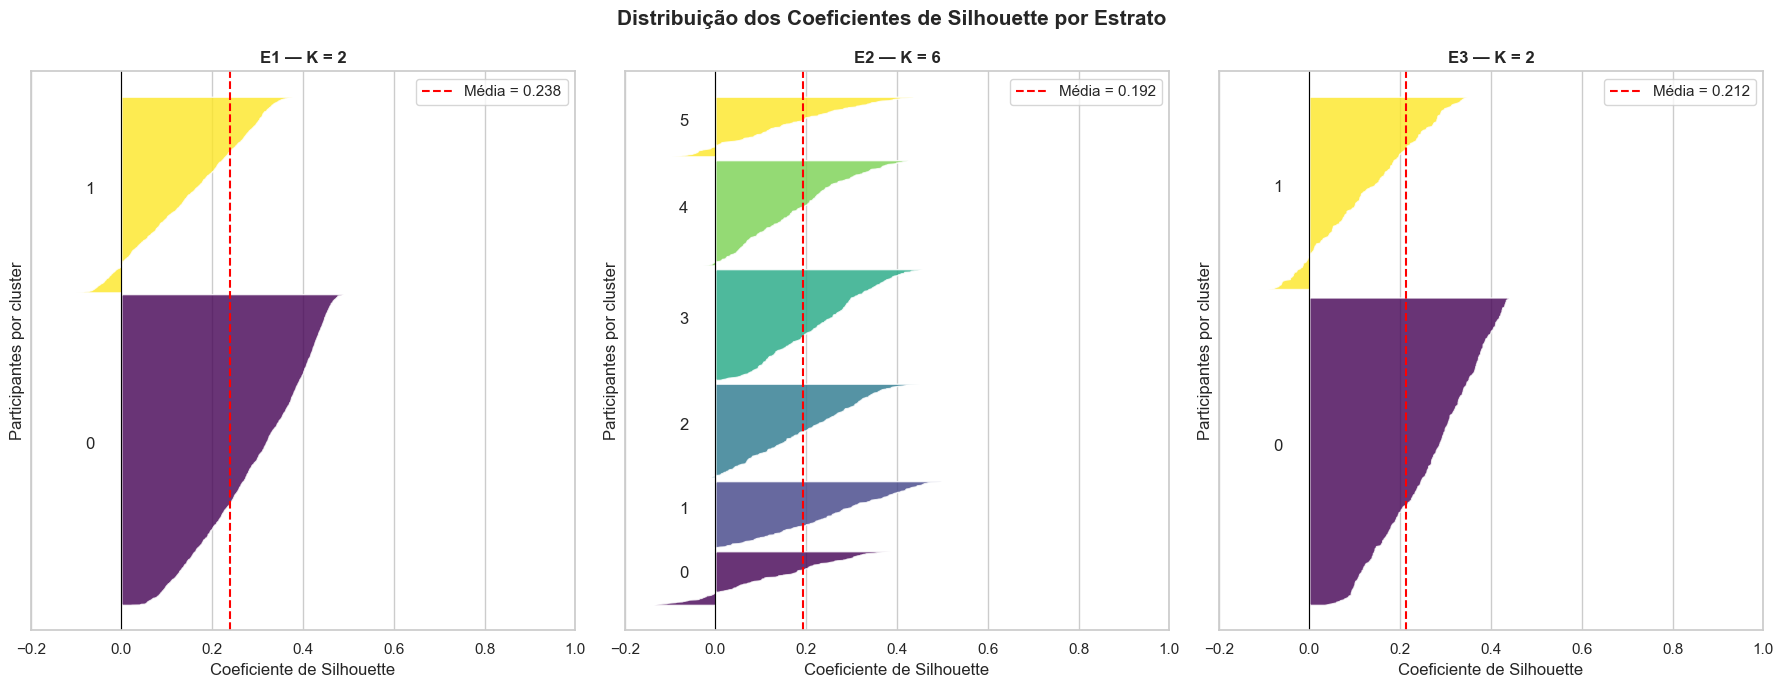

In [10]:

import joblib
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import silhouette_samples

PASTA_MODELOS = Path("../modelosclusterizacao")

estratos = [
    ("E1", "HbA1c < 5.7", "estrato_1"),
    ("E2", "5.7 <= HbA1c < 6.5", "estrato_2"),
    ("E3", "HbA1c >= 6.5", "estrato_3")
]

fig, axes = plt.subplots(1, 3, figsize=(18, 7))

for ax, (codigo, nome_estrato, arquivo_modelo) in zip(
    axes, estratos
):
    artefato = joblib.load(
        PASTA_MODELOS / f"{arquivo_modelo}_kmeans.joblib"
    )

    scaler = artefato["scaler"]
    modelo = artefato["modelo"]
    variaveis = artefato["features"]

    dados = df[df["estrato_hba1c"] == nome_estrato].copy()

    X_scaled = scaler.transform(dados[variaveis])
    labels = modelo.predict(X_scaled)

    valores_silhouette = silhouette_samples(
        X_scaled, labels
    )

    media = valores_silhouette.mean()

    y_inicial = 10

    for cluster in sorted(np.unique(labels)):
        valores_cluster = np.sort(
            valores_silhouette[labels == cluster]
        )

        tamanho = len(valores_cluster)
        y_final = y_inicial + tamanho

        cor = plt.cm.viridis(
            cluster / max(1, modelo.n_clusters - 1)
        )

        ax.fill_betweenx(
            np.arange(y_inicial, y_final),
            0,
            valores_cluster,
            facecolor=cor,
            alpha=0.8
        )

        ax.text(
            -0.08,
            y_inicial + tamanho / 2,
            str(cluster)
        )

        y_inicial = y_final + 10

    ax.axvline(
        media,
        color="red",
        linestyle="--",
        label=f"Média = {media:.3f}"
    )

    ax.axvline(0, color="black", linewidth=0.8)

    ax.set_title(
        f"{codigo} — K = {modelo.n_clusters}",
        fontweight="bold"
    )

    ax.set_xlabel("Coeficiente de Silhouette")
    ax.set_ylabel("Participantes por cluster")
    ax.set_yticks([])
    ax.set_xlim(-0.2, 1.0)
    ax.legend()

fig.suptitle(
    "Distribuição dos Coeficientes de Silhouette por Estrato",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



### Interpretação dos Silhouette Diagrams

A análise dos coeficientes individuais de Silhouette
evidenciou diferenças na qualidade da separação dos
agrupamentos identificados pelo K-Means.

No Estrato 1 (K = 2), foi observado Silhouette Score
médio de 0,238, com predominância de coeficientes
positivos, embora parte dos participantes apresente
valores próximos de zero ou negativos.

No Estrato 2 (K = 6), o Silhouette Score médio foi
de 0,192. Os seis clusters apresentaram diferentes
distribuições de coeficientes, incluindo observações
com valores negativos, especialmente nos clusters
0 e 5.

No Estrato 3 (K = 2), o Silhouette Score médio foi
de 0,212, com predominância de valores positivos
e presença de observações próximas às fronteiras
entre os agrupamentos.

De maneira geral, os resultados indicam separação
limitada entre os clusters, com sobreposição de
características cardiometabólicas.

Dessa forma, os agrupamentos devem ser interpretados
como subperfis descritivos exploratórios, e não como
categorias clínicas independentes ou diagnósticas.



# 3. Visualização dos Agrupamentos

## 3.1. Projeção Bidimensional com PCA

A Análise de Componentes Principais (PCA) foi utilizada
para representar os agrupamentos em duas dimensões.

O PCA reduz a dimensionalidade dos dados, preservando
a maior quantidade possível de variância nas primeiras
componentes principais.

A transformação foi aplicada separadamente em cada
estrato, utilizando os dados previamente transformados
pelo RobustScaler.

As cores representam os clusters atribuídos pelo
K-Means no espaço original de cinco variáveis.

A projeção bidimensional é utilizada exclusivamente
para visualização e não substitui as métricas de
avaliação dos agrupamentos.


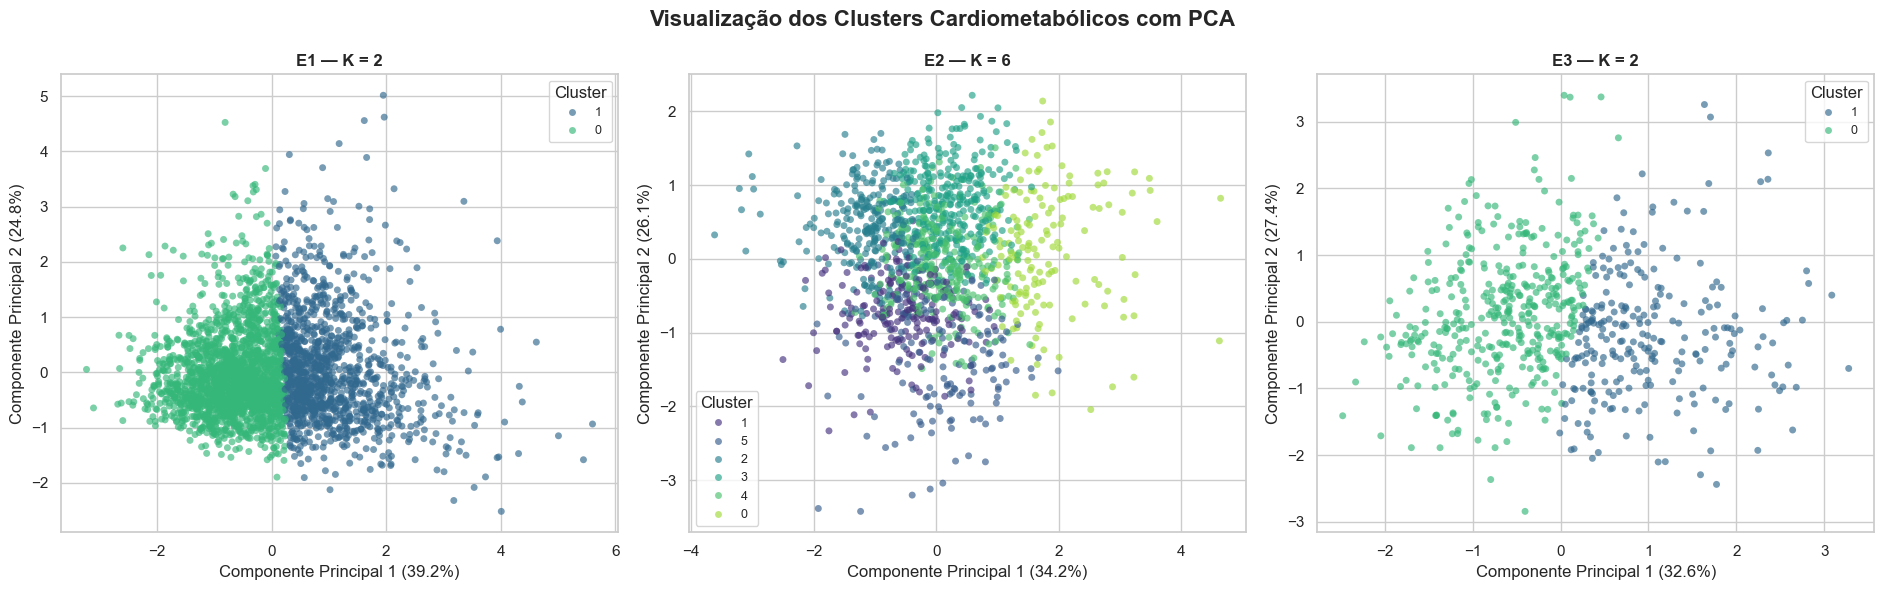

In [11]:

from sklearn.decomposition import PCA

fig, axes = plt.subplots(1, 3, figsize=(19, 6))

for ax, (codigo, nome_estrato, arquivo_modelo) in zip(
    axes, estratos
):
    artefato = joblib.load(
        PASTA_MODELOS / f"{arquivo_modelo}_kmeans.joblib"
    )

    scaler = artefato["scaler"]
    modelo = artefato["modelo"]
    variaveis = artefato["features"]

    dados = df[
        df["estrato_hba1c"] == nome_estrato
    ].copy()

    X_scaled = scaler.transform(dados[variaveis])

    # PCA somente para visualização
    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X_scaled)

    labels = modelo.predict(X_scaled)

    sns.scatterplot(
        x=X_pca[:, 0],
        y=X_pca[:, 1],
        hue=labels.astype(str),
        palette="viridis",
        s=25,
        alpha=0.65,
        linewidth=0,
        ax=ax
    )

    variancia = pca.explained_variance_ratio_ * 100

    ax.set_title(
        f"{codigo} — K = {modelo.n_clusters}",
        fontweight="bold"
    )

    ax.set_xlabel(
        f"Componente Principal 1 ({variancia[0]:.1f}%)"
    )

    ax.set_ylabel(
        f"Componente Principal 2 ({variancia[1]:.1f}%)"
    )

    ax.legend(
        title="Cluster",
        fontsize=9
    )

fig.suptitle(
    "Visualização dos Clusters Cardiometabólicos com PCA",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



### Interpretação da Projeção PCA

A Análise de Componentes Principais (PCA) foi utilizada
para visualizar os agrupamentos cardiometabólicos em
duas dimensões, preservando as classificações originais
obtidas pelo K-Means.

No Estrato 1, as duas primeiras componentes explicaram
aproximadamente 64,0% da variância dos dados transformados.
Os dois clusters apresentaram regiões de concentração
distintas, principalmente ao longo da primeira componente,
embora exista sobreposição na região central.

No Estrato 2, as duas primeiras componentes explicaram
aproximadamente 60,3% da variância. Os seis clusters
apresentaram distribuições parcialmente distintas,
mas com sobreposição considerável entre os agrupamentos.

No Estrato 3, as duas primeiras componentes explicaram
aproximadamente 60,0% da variância, sendo observada
separação parcial entre os dois clusters, acompanhada
de sobreposição na região central.

De maneira geral, os resultados visuais são coerentes
com os Silhouette Scores obtidos anteriormente, que
indicaram separação limitada entre os agrupamentos.

É importante destacar que a projeção PCA não representa
integralmente as cinco dimensões utilizadas pelo K-Means.
Portanto, a sobreposição observada nos gráficos não
implica necessariamente sobreposição equivalente no
espaço original das variáveis.



## 3.2. Contribuição das Variáveis para as Componentes Principais

Para auxiliar na interpretação da projeção PCA, foram
analisados os coeficientes das variáveis nas duas
primeiras componentes principais.

Esses coeficientes permitem identificar quais variáveis
apresentam maior participação na orientação de cada
componente.

Como o PCA foi ajustado separadamente para cada estrato,
as componentes podem representar combinações diferentes
de variáveis em cada grupo.


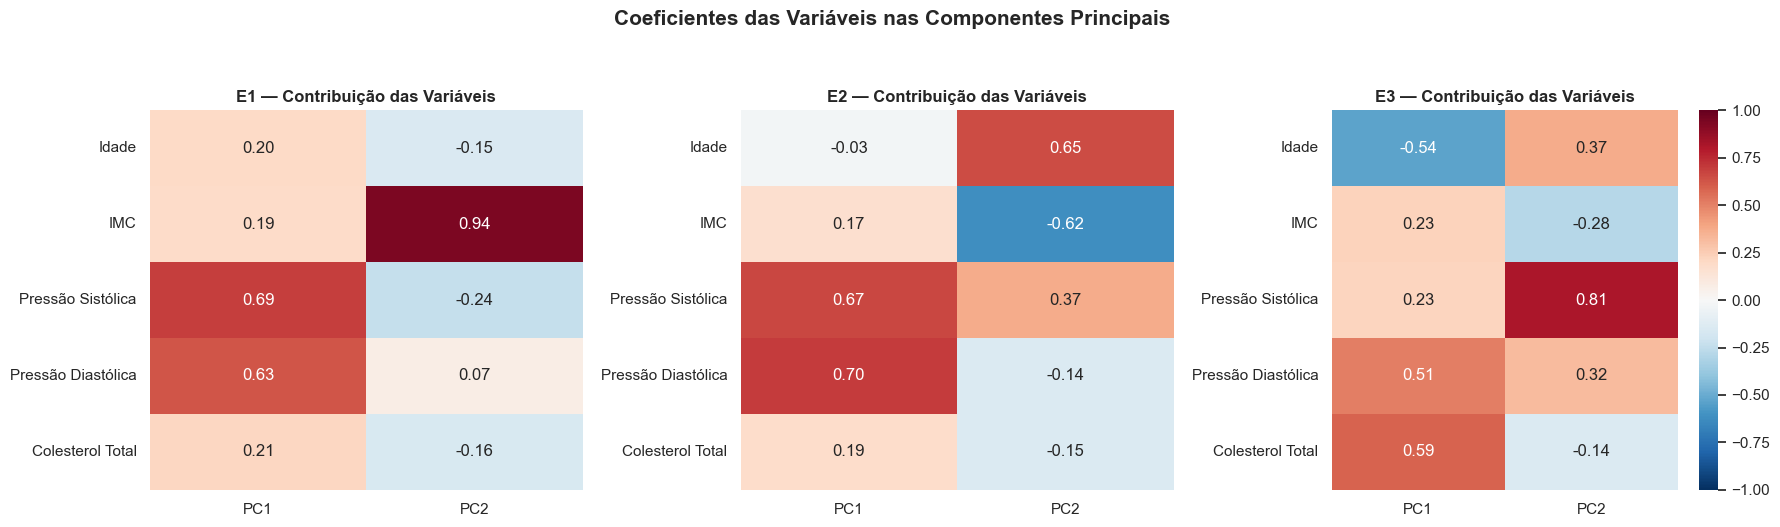

In [12]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (codigo, nome_estrato, arquivo_modelo) in zip(
    axes, estratos
):
    artefato = joblib.load(
        PASTA_MODELOS / f"{arquivo_modelo}_kmeans.joblib"
    )

    scaler = artefato["scaler"]
    variaveis = artefato["features"]

    dados = df[
        df["estrato_hba1c"] == nome_estrato
    ]

    X_scaled = scaler.transform(dados[variaveis])

    pca = PCA(n_components=2)
    pca.fit(X_scaled)

    componentes = pd.DataFrame(
        pca.components_.T,
        index=[nomes_variaveis[v] for v in variaveis],
        columns=["PC1", "PC2"]
    )

    sns.heatmap(
        componentes,
        annot=True,
        fmt=".2f",
        cmap="RdBu_r",
        center=0,
        vmin=-1,
        vmax=1,
        ax=ax,
        cbar=(codigo == "E3")
    )

    ax.set_title(
        f"{codigo} — Contribuição das Variáveis",
        fontweight="bold"
    )

fig.suptitle(
    "Coeficientes das Variáveis nas Componentes Principais",
    fontsize=15,
    fontweight="bold",
    y=1.05
)

plt.tight_layout()
plt.show()



### Interpretação das Componentes Principais

A análise dos coeficientes das componentes principais
permitiu identificar as variáveis com maior participação
nas projeções bidimensionais de cada estrato.

No Estrato 1, a primeira componente (PC1) apresentou
maiores coeficientes para pressão sistólica (0,69) e
pressão diastólica (0,63), enquanto a segunda componente
(PC2) foi predominantemente associada ao IMC (0,94).

No Estrato 2, a PC1 também apresentou maiores coeficientes
para pressão diastólica (0,70) e sistólica (0,67).
A PC2 apresentou um contraste entre idade (0,65)
e IMC (-0,62).

No Estrato 3, a PC1 apresentou maiores coeficientes
para colesterol total (0,59), idade (-0,54) e pressão
diastólica (0,51). A PC2 foi predominantemente
associada à pressão sistólica (0,81).

Esses resultados indicam que as principais direções
de variabilidade diferem entre os estratos de HbA1c.

Os coeficientes auxiliam na interpretação visual do PCA,
mas não representam diretamente a importância das
variáveis para o algoritmo K-Means.

Como o PCA foi ajustado separadamente em cada estrato,
suas componentes não são diretamente equivalentes.



# 4. Caracterização dos Perfis Cardiometabólicos

## 4.1. Distribuição dos Participantes por Perfil

Após a seleção do número de clusters, foram identificados
dez subperfis cardiometabólicos distribuídos entre os
três estratos de HbA1c.

Nesta etapa, é analisada a quantidade de participantes
pertencentes a cada perfil, permitindo observar a
distribuição dos agrupamentos.


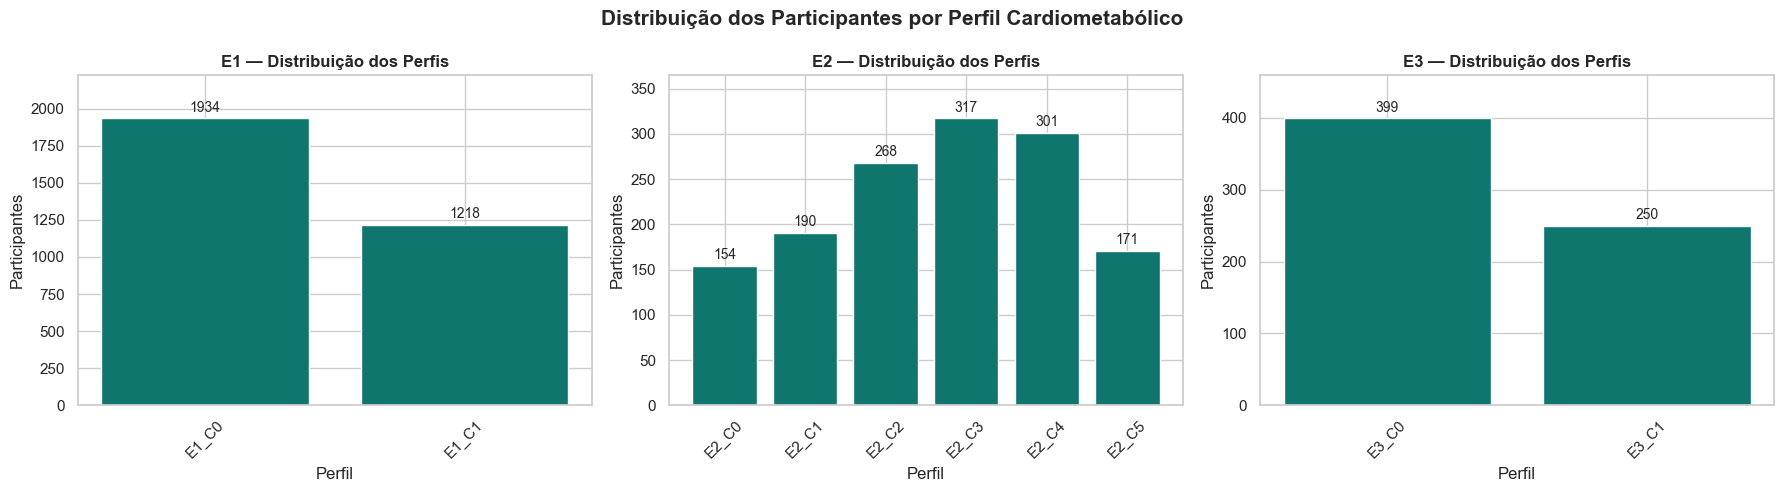

In [13]:

contagem_perfis = (
    df.groupby(["estrato_hba1c", "perfil_id"])
    .size()
    .reset_index(name="participantes")
)

ordem_perfis = (
    contagem_perfis
    .sort_values(["estrato_hba1c", "perfil_id"])
)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (codigo, nome_estrato, _) in zip(axes, estratos):
    dados = ordem_perfis[
        ordem_perfis["estrato_hba1c"] == nome_estrato
    ].sort_values("perfil_id")

    barras = ax.bar(
        dados["perfil_id"],
        dados["participantes"],
        color="#0E766D"
    )

    for barra in barras:
        altura = barra.get_height()

        ax.annotate(
            f"{int(altura)}",
            xy=(
                barra.get_x() + barra.get_width() / 2,
                altura
            ),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            fontsize=10
        )

    ax.set_title(
        f"{codigo} — Distribuição dos Perfis",
        fontweight="bold"
    )

    ax.set_xlabel("Perfil")
    ax.set_ylabel("Participantes")
    ax.set_ylim(
        0,
        dados["participantes"].max() * 1.15
    )

    ax.tick_params(axis="x", rotation=45)

fig.suptitle(
    "Distribuição dos Participantes por Perfil Cardiometabólico",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



### Interpretação da Distribuição dos Perfis

A clusterização identificou dez subperfis cardiometabólicos,
distribuídos entre os três estratos de HbA1c.

No Estrato 1 (n = 3.152), foram identificados dois clusters,
com 1.934 e 1.218 participantes, respectivamente.

No Estrato 2 (n = 1.401), foram identificados seis clusters,
com tamanhos variando entre 154 e 317 participantes.
A distribuição demonstra maior diversidade de agrupamentos
nesse estrato.

No Estrato 3 (n = 649), foram identificados dois clusters,
com 399 e 250 participantes, respectivamente.

Os diferentes tamanhos dos clusters devem ser considerados
na interpretação das características de cada perfil.

A quantidade de participantes em cada agrupamento não
representa sua prevalência na população geral, pois
a análise utiliza uma amostra selecionada do NHANES.



## 4.2. Comparação dos Perfis com Radar Charts

Os Radar Charts foram utilizados para comparar as
características cardiometabólicas dos clusters dentro
de cada estrato de HbA1c.

Para permitir a comparação entre variáveis com unidades
diferentes, foram calculadas as medianas de cada variável
por cluster.

Em seguida, essas medianas foram centralizadas pela
mediana do respectivo estrato e divididas pelo seu
intervalo interquartil (IQR).

Dessa forma, os valores representam desvios relativos
à distribuição do próprio estrato, e não valores
clínicos absolutos.

Os gráficos possuem finalidade descritiva e não
representam escalas de risco cardiovascular.


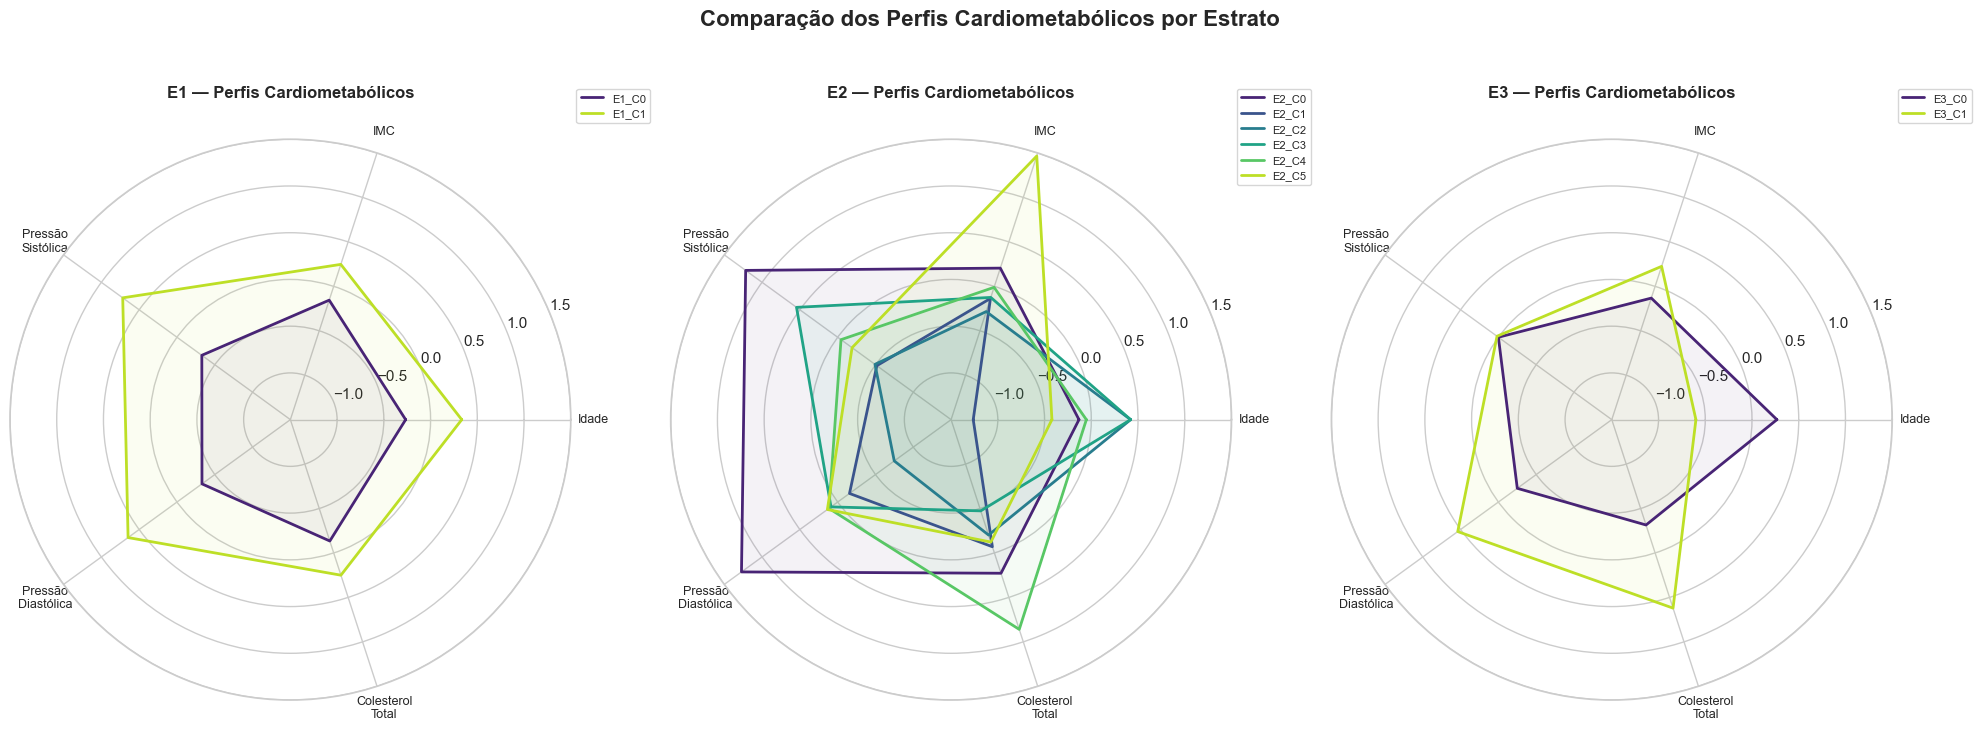

In [14]:
features = [
    "idade",
    "imc",
    "pressao_sistolica",
    "pressao_diastolica",
    "colesterol_total"
]

rotulos = [
    "Idade",
    "IMC",
    "Pressão\nSistólica",
    "Pressão\nDiastólica",
    "Colesterol\nTotal"
]

estratos_radar = [
    ("E1", "HbA1c < 5.7"),
    ("E2", "5.7 <= HbA1c < 6.5"),
    ("E3", "HbA1c >= 6.5")
]

# Guardar os valores padronizados de cada estrato
dados_radar = {}

for codigo, nome_estrato in estratos_radar:

    dados = df[
        df["estrato_hba1c"] == nome_estrato
    ].copy()

    mediana_estrato = dados[features].median()

    iqr_estrato = (
        dados[features].quantile(0.75)
        - dados[features].quantile(0.25)
    )

    if (iqr_estrato == 0).any():
        raise ValueError(
            f"IQR igual a zero no estrato {codigo}"
        )

    medianas_clusters = (
        dados.groupby("perfil_id")[features].median()
    )

    valores_padronizados = (
        (medianas_clusters - mediana_estrato)
        / iqr_estrato
    )

    dados_radar[codigo] = valores_padronizados

# Definir uma escala radial comum aos três gráficos
todos_valores = pd.concat(dados_radar.values())

limite = max(
    1.0,
    np.ceil(
        np.abs(todos_valores.to_numpy()).max() * 10
    ) / 10
)

# Preparar os ângulos do radar
N = len(features)

angulos = np.linspace(
    0, 2 * np.pi, N, endpoint=False
).tolist()

angulos += angulos[:1]

fig, axes = plt.subplots(
    1, 3,
    figsize=(20, 7),
    subplot_kw={"polar": True}
)

for ax, (codigo, nome_estrato) in zip(
    axes, estratos_radar
):
    tabela = dados_radar[codigo]

    cores = plt.cm.viridis(
        np.linspace(0.1, 0.9, len(tabela))
    )

    for cor, (perfil, linha) in zip(
        cores, tabela.iterrows()
    ):
        valores = linha.tolist()
        valores += valores[:1]

        ax.plot(
            angulos,
            valores,
            linewidth=2,
            label=perfil,
            color=cor
        )

        ax.fill(
            angulos,
            valores,
            alpha=0.06,
            color=cor
        )

    ax.set_xticks(angulos[:-1])
    ax.set_xticklabels(rotulos, fontsize=9)

    ax.set_ylim(-limite, limite)

    ax.set_title(
        f"{codigo} — Perfis Cardiometabólicos",
        fontweight="bold",
        pad=30
    )

    ax.legend(
        loc="upper left",
        bbox_to_anchor=(1.0, 1.1),
        fontsize=8
    )

fig.suptitle(
    "Comparação dos Perfis Cardiometabólicos por Estrato",
    fontsize=16,
    fontweight="bold",
    y=1.05
)

plt.tight_layout()
plt.show()



### Interpretação dos Radar Charts

Os Radar Charts permitiram comparar as características
cardiometabólicas dos perfis identificados dentro de
cada estrato de HbA1c.

No Estrato 1, foram observados dois perfis com diferenças
nas medianas das cinco variáveis, sendo o E1_C1
caracterizado por valores relativamente maiores.

No Estrato 2, foram identificados padrões distintos,
incluindo perfis com maiores valores de pressão arterial
(E2_C0), colesterol total (E2_C4) e IMC (E2_C5).

Também foram observados perfis caracterizados por
diferenças de idade e pressão arterial, evidenciando
a heterogeneidade dos agrupamentos nesse estrato.

No Estrato 3, os dois perfis apresentaram diferenças
principalmente em idade, IMC, pressão diastólica
e colesterol total, enquanto as medianas de pressão
sistólica permaneceram próximas.

Os valores apresentados foram padronizados em relação
à mediana e ao intervalo interquartil de cada estrato.

Portanto, os gráficos representam diferenças relativas
entre os perfis e não medidas absolutas de risco clínico.

A interpretação deve considerar a sobreposição entre
os agrupamentos identificada nas análises de Silhouette.



## 4.3. Caracterização Comportamental dos Perfis

Além das variáveis utilizadas na clusterização,
foram analisados indicadores de atividade física
e comportamento sedentário dos participantes.

As variáveis consideradas foram:

- Minutos semanais de atividade física moderada;
- Minutos semanais de atividade física vigorosa;
- Minutos diários de comportamento sedentário.

Essas variáveis não participaram do treinamento
do K-Means e foram utilizadas exclusivamente
para caracterização complementar dos perfis.

A análise tem caráter exploratório e não permite
estabelecer relações causais entre comportamento
e características cardiometabólicas.


In [15]:

variaveis_comportamentais = [
    "atv_moderada_min_semana",
    "atv_vigorosa_min_semana",
    "minutos_sedentarios_dia"
]

resumo_comportamental = df[
    variaveis_comportamentais
].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).T

resumo_comportamental["percentual_zero"] = (
    df[variaveis_comportamentais]
    .eq(0)
    .mean()
    * 100
)

display(resumo_comportamental.round(2))


,count,mean,std,min,25%,50%,75%,90%,99%,max,percentual_zero
atv_moderada_min_semana,5202.0,219.31,384.68,0.0,23.1,120.0,240.0,480.0,1800.0,6300.0,19.24
atv_vigorosa_min_semana,5202.0,68.69,207.69,0.0,0.0,0.0,60.0,180.0,840.0,4500.0,54.17
minutos_sedentarios_dia,5202.0,364.65,207.89,0.0,180.0,300.0,480.0,660.0,960.0,1380.0,0.06



### 4.3.1. Participação em Atividades Físicas

Foi analisada a proporção de participantes com registro
positivo de atividade física moderada e vigorosa em
cada perfil cardiometabólico.

A utilização de proporções permite considerar a elevada
frequência de valores iguais a zero, especialmente na
variável de atividade vigorosa.

Um valor positivo indica apenas a presença de minutos
registrados de atividade, não necessariamente o
cumprimento de recomendações de atividade física.

As variáveis comportamentais não participaram da
formação dos clusters.


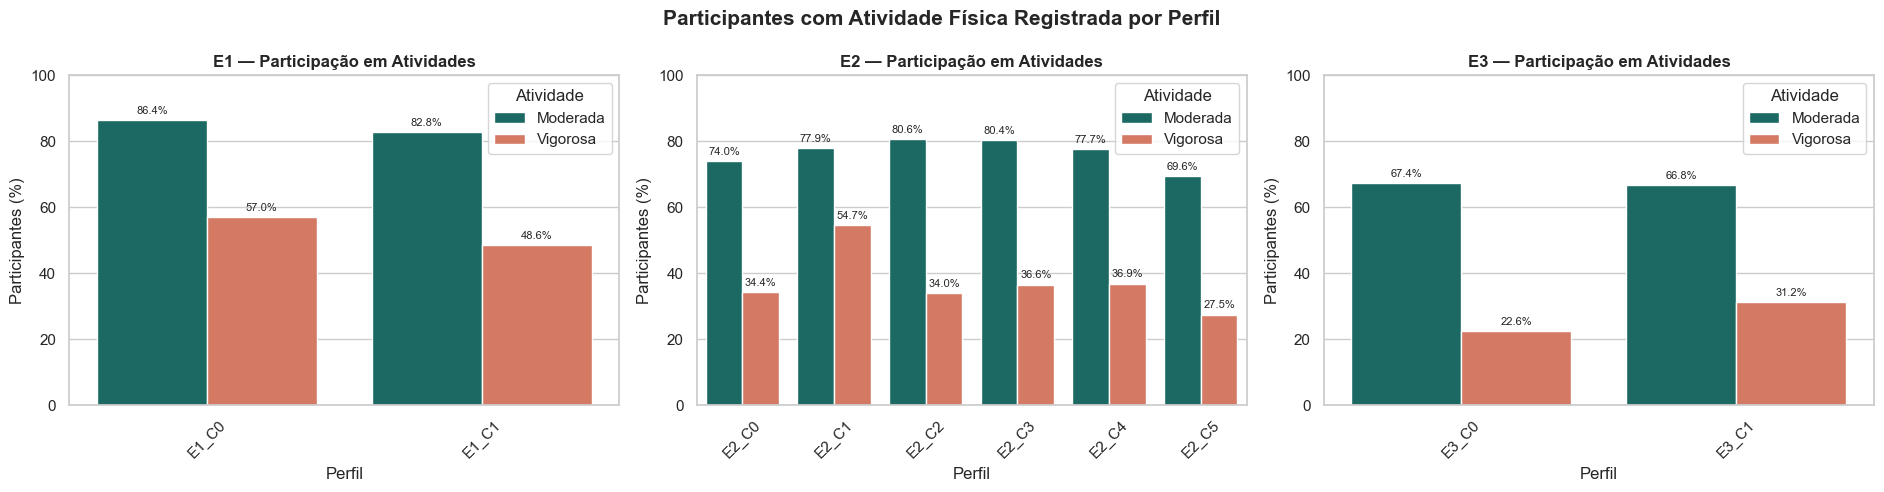

In [16]:

# Criar indicadores de atividade registrada
df_comportamento = df.copy()

df_comportamento["moderada_positiva"] = (
    df_comportamento["atv_moderada_min_semana"] > 0
)

df_comportamento["vigorosa_positiva"] = (
    df_comportamento["atv_vigorosa_min_semana"] > 0
)

# Calcular percentual por perfil
participacao = (
    df_comportamento
    .groupby(["estrato_hba1c", "perfil_id"])
    [["moderada_positiva", "vigorosa_positiva"]]
    .mean()
    .mul(100)
    .reset_index()
)

# Transformar em formato longo
participacao_long = participacao.melt(
    id_vars=["estrato_hba1c", "perfil_id"],
    value_vars=["moderada_positiva", "vigorosa_positiva"],
    var_name="atividade",
    value_name="percentual"
)

participacao_long["atividade"] = (
    participacao_long["atividade"].map({
        "moderada_positiva": "Moderada",
        "vigorosa_positiva": "Vigorosa"
    })
)

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

for ax, (codigo, nome_estrato, _) in zip(axes, estratos):

    dados = participacao_long[
        participacao_long["estrato_hba1c"] == nome_estrato
    ]

    sns.barplot(
        data=dados,
        x="perfil_id",
        y="percentual",
        hue="atividade",
        palette={
            "Moderada": "#0E766D",
            "Vigorosa": "#E76F51"
        },
        errorbar=None,
        ax=ax
    )

    ax.set_title(
        f"{codigo} — Participação em Atividades",
        fontweight="bold"
    )

    ax.set_xlabel("Perfil")
    ax.set_ylabel("Participantes (%)")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=45)

    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.1f%%",
            padding=3,
            fontsize=8
        )

    ax.legend(title="Atividade")

fig.suptitle(
    "Participantes com Atividade Física Registrada por Perfil",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



### Interpretação da Participação em Atividades Físicas

A análise complementar identificou diferenças na proporção
de participantes com atividade física registrada entre
os perfis cardiometabólicos.

No Estrato 1, o perfil E1_C0 apresentou maior proporção
de atividade moderada (86,4%) e vigorosa (57,0%) em
comparação ao E1_C1 (82,8% e 48,6%, respectivamente).

No Estrato 2, o perfil E2_C1 apresentou a maior proporção
de participantes com atividade vigorosa registrada
(54,7%). Em contrapartida, o E2_C5, caracterizado por
IMC relativamente elevado, apresentou os menores
percentuais de atividade moderada (69,6%) e vigorosa
(27,5%) dentro do estrato.

No Estrato 3, os dois perfis apresentaram proporções
semelhantes de atividade moderada. Entretanto, a
atividade vigorosa foi mais frequente no E3_C1 (31,2%)
do que no E3_C0 (22,6%).

Esses resultados demonstram que os perfis identificados
pelo K-Means também apresentam diferenças descritivas
em variáveis comportamentais que não participaram
da formação dos agrupamentos.

As associações observadas não permitem estabelecer
relações causais, tampouco demonstram diferenças
estatisticamente significativas entre os perfis.

Os percentuais representam participantes com valores
positivos registrados nas respectivas variáveis,
não necessariamente o cumprimento de recomendações
de atividade física.



### 4.3.2. Duração das Atividades e Comportamento Sedentário

Além da presença de atividade física registrada, foi
analisada a duração semanal das atividades moderada
e vigorosa em cada perfil cardiometabólico.

Para evitar que a elevada frequência de zeros
mascarasse a distribuição dos minutos de atividade,
as medianas foram calculadas entre participantes
com valores positivos.

O tempo sedentário foi analisado considerando todos
os participantes de cada perfil.

Essa análise permite complementar a caracterização
comportamental dos agrupamentos, sem modificar
os clusters previamente identificados.


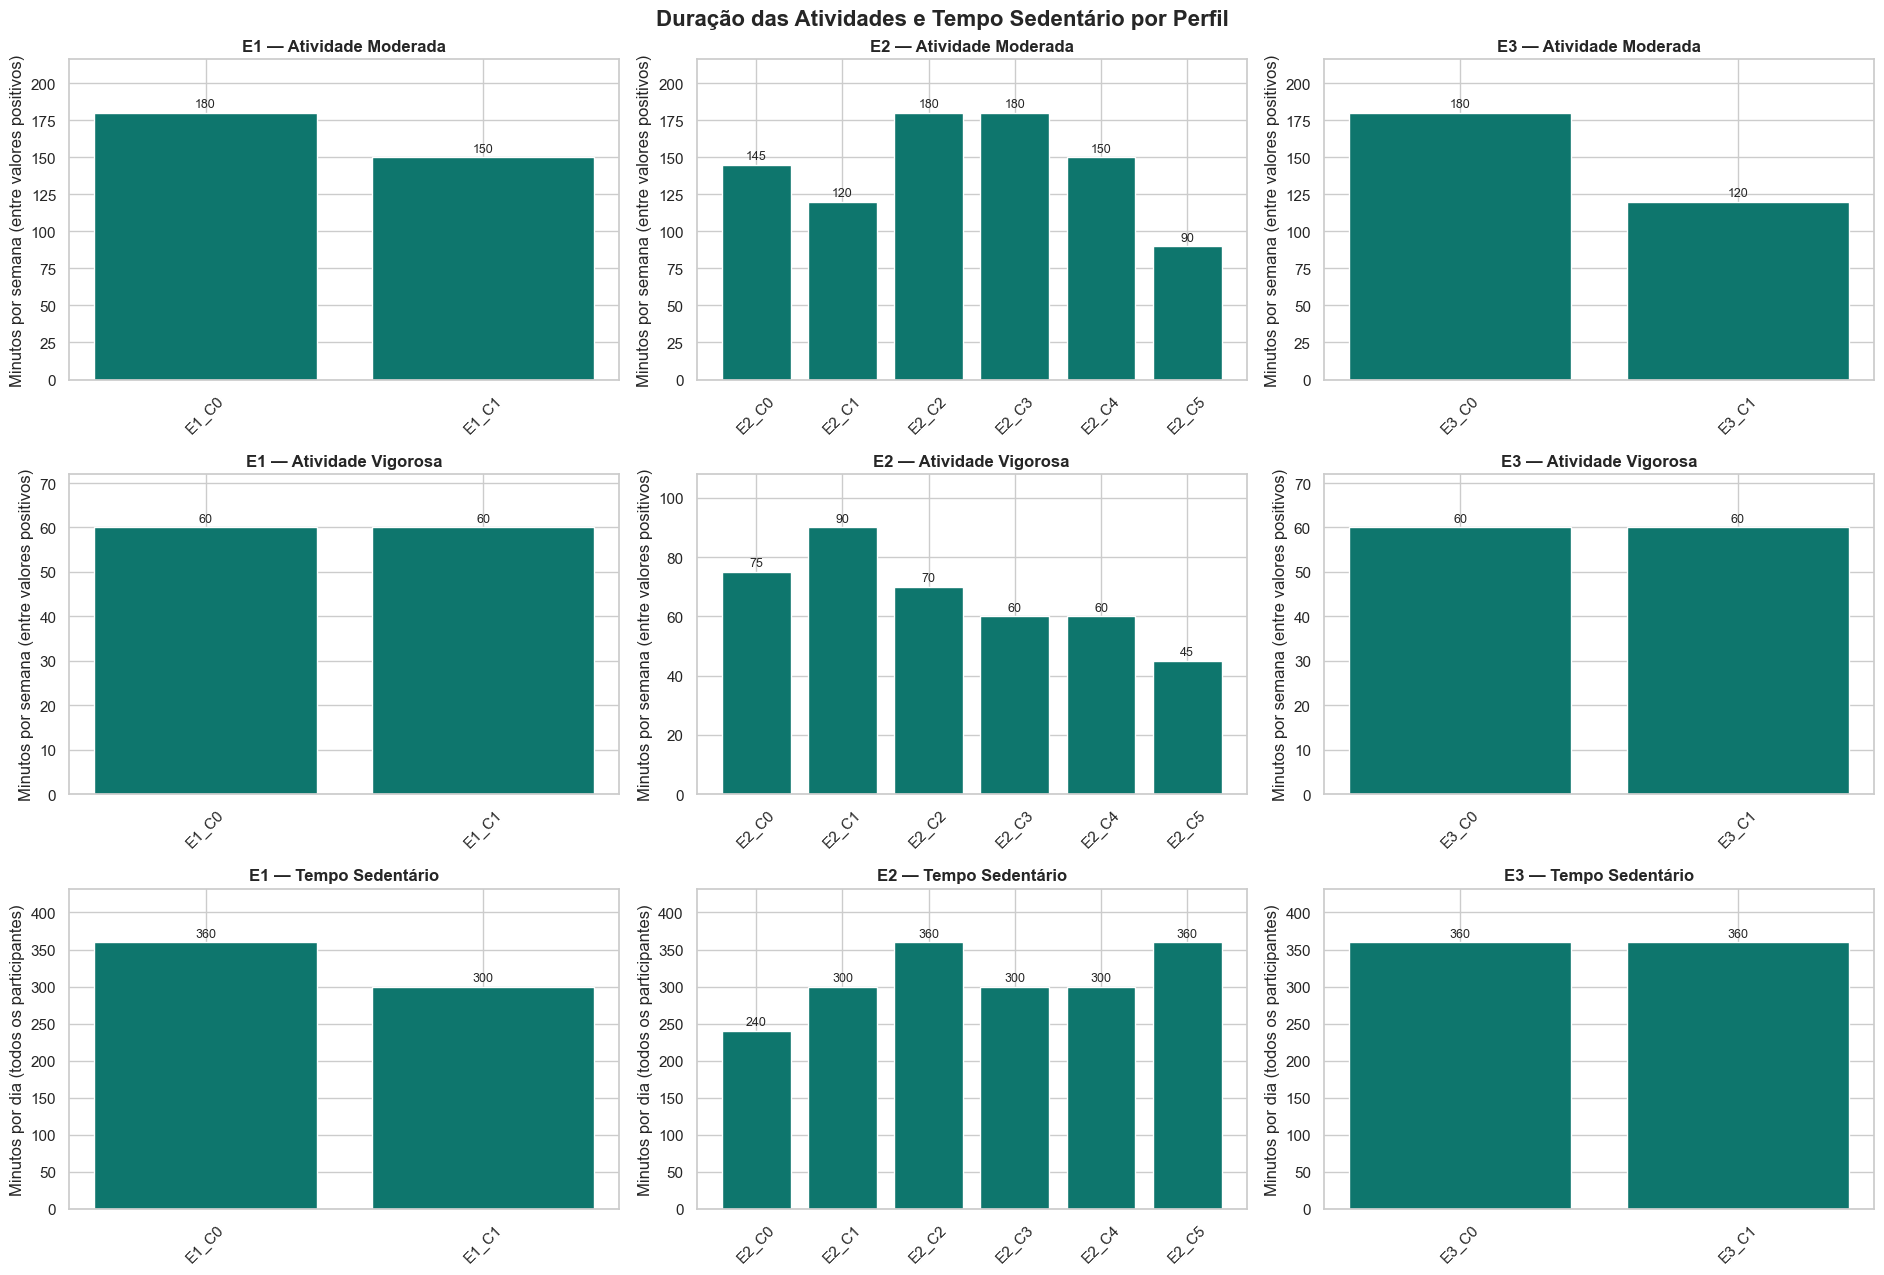

In [20]:


def mediana_positivos(serie):
    valores = serie[serie > 0]
    return valores.median() if len(valores) else np.nan

resumo_duracao = (
    df.groupby(["estrato_hba1c", "perfil_id"])
    .agg(
        moderada_min=("atv_moderada_min_semana", mediana_positivos),
        vigorosa_min=("atv_vigorosa_min_semana", mediana_positivos),
        sedentario_min=("minutos_sedentarios_dia", "median")
    )
    .reset_index()
)



indicadores = {
    "moderada_min": (
        "Atividade Moderada",
        "Minutos por semana (entre valores positivos)"
    ),
    "vigorosa_min": (
        "Atividade Vigorosa",
        "Minutos por semana (entre valores positivos)"
    ),
    "sedentario_min": (
        "Tempo Sedentário",
        "Minutos por dia (todos os participantes)"
    )
}

fig, axes = plt.subplots(3, 3, figsize=(19, 13))

for i, (variavel, (titulo, unidade)) in enumerate(
    indicadores.items()
):
    for j, (codigo, nome_estrato, _) in enumerate(estratos):

        ax = axes[i, j]

        dados = resumo_duracao[
            resumo_duracao["estrato_hba1c"] == nome_estrato
        ].sort_values("perfil_id")

        barras = ax.bar(
            dados["perfil_id"],
            dados[variavel],
            color="#0E766D"
        )

        for barra in barras:
            altura = barra.get_height()

            if np.isfinite(altura):
                ax.annotate(
                    f"{altura:.0f}",
                    xy=(
                        barra.get_x() + barra.get_width() / 2,
                        altura
                    ),
                    xytext=(0, 4),
                    textcoords="offset points",
                    ha="center",
                    fontsize=9
                )

        ax.set_title(
            f"{codigo} — {titulo}",
            fontweight="bold"
        )

        ax.set_ylabel(unidade)
        ax.tick_params(axis="x", rotation=45)

        if dados[variavel].notna().any():
            ax.set_ylim(
                0,
                dados[variavel].max() * 1.2
            )

fig.suptitle(
    "Duração das Atividades e Tempo Sedentário por Perfil",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()




### Interpretação da Duração das Atividades e do Tempo Sedentário

A análise complementar da duração das atividades físicas
identificou diferenças descritivas entre os perfis
cardiometabólicos dos três estratos de HbA1c.

No Estrato 1, o perfil E1_C0 apresentou maior mediana
de atividade moderada (180 min/semana) em comparação
ao E1_C1 (150 min/semana), considerando apenas
participantes com valores positivos. A mediana de
atividade vigorosa foi de 60 minutos em ambos os perfis.
O tempo sedentário foi maior no E1_C0 (360 min/dia).

No Estrato 2, o perfil E2_C5, caracterizado por IMC
relativamente elevado, apresentou as menores medianas
de atividade moderada (90 min/semana) e vigorosa
(45 min/semana) entre participantes com atividade
registrada. Esse perfil também apresentou mediana
de 360 minutos diários de comportamento sedentário.

O perfil E2_C1 apresentou a maior mediana de atividade
vigorosa (90 min/semana), enquanto E2_C2 e E2_C3
apresentaram as maiores medianas de atividade moderada
(180 min/semana).

No Estrato 3, o E3_C0 apresentou maior mediana de
atividade moderada (180 min/semana) em comparação
ao E3_C1 (120 min/semana). As medianas de atividade
vigorosa e tempo sedentário foram iguais entre
os dois perfis.

Os resultados demonstram diferenças comportamentais
descritivas entre os agrupamentos, mesmo sem a inclusão
dessas variáveis no treinamento do K-Means.

As medianas de atividade física foram calculadas
exclusivamente entre participantes com valores
positivos, enquanto o tempo sedentário considerou
todos os participantes.

As diferenças observadas não permitem estabelecer
relações causais nem comprovar diferenças
estatisticamente significativas entre os perfis.



# 5. Discussão dos Resultados

A aplicação do K-Means permitiu identificar dez subperfis
cardiometabólicos distribuídos entre três estratos de HbA1c,
utilizando informações de 5.202 participantes do NHANES
2021–2023.

A estratégia de realizar a clusterização separadamente
em cada estrato permitiu investigar a heterogeneidade
das características cardiometabólicas dentro de
diferentes faixas de hemoglobina glicada.

Os agrupamentos apresentaram diferenças descritivas
em idade, IMC, pressão arterial sistólica, pressão
arterial diastólica e colesterol total.

O Estrato 2 apresentou maior diversidade de perfis,
incluindo agrupamentos caracterizados por valores
relativamente elevados de pressão arterial, IMC
ou colesterol total.

A análise complementar das variáveis comportamentais
identificou diferenças na frequência e duração de
atividade física entre os perfis, mesmo sem a utilização
dessas variáveis na formação dos clusters.

Os resultados de Silhouette indicaram separação
limitada entre os agrupamentos, com coeficientes
médios de aproximadamente 0,19 a 0,24.

Por outro lado, os experimentos de estabilidade
por reamostragem demonstraram concordância
relativamente elevada com os agrupamentos de
referência, sugerindo reprodutibilidade das
atribuições sob as condições avaliadas.

Esses resultados não são contraditórios: um
agrupamento pode apresentar estabilidade relativa
e, simultaneamente, sobreposição entre seus clusters.

Dessa forma, os perfis identificados devem ser
interpretados como agrupamentos exploratórios
e descritivos, sem equivalência direta com
categorias diagnósticas ou prognósticas.



## 5.1. Limitações do Estudo

Apesar dos resultados obtidos, algumas limitações
devem ser consideradas:

1. **Separação limitada entre clusters:** os valores
   relativamente baixos de Silhouette indicam
   sobreposição entre os perfis identificados.

2. **Natureza exploratória:** o K-Means identifica
   agrupamentos com base em distâncias, não
   estabelecendo diagnósticos ou níveis de risco.

3. **Dados transversais:** o NHANES utilizado
   representa observações de um período específico,
   não permitindo estabelecer relações causais
   ou acompanhar mudanças individuais ao longo do tempo.

4. **Representatividade:** os dados são provenientes
   de participantes dos Estados Unidos. Além disso,
   não foram incorporados pesos e características
   do desenho amostral complexo do NHANES nesta análise.
   Portanto, os resultados não devem ser interpretados
   como estimativas populacionais, nem generalizados
   diretamente para a população brasileira.

5. **Seleção de participantes:** a utilização de
   registros completos pode introduzir diferenças
   entre a amostra analisada e os participantes
   excluídos por ausência de informações.

6. **Variáveis não consideradas:** fatores como
   medicamentos, histórico clínico e outras
   características individuais podem influenciar
   os indicadores cardiometabólicos observados.

7. **Variáveis comportamentais:** os indicadores de
   atividade física e sedentarismo foram utilizados
   apenas para caracterização complementar, sem
   controle de potenciais fatores de confusão.

8. **Valores extremos:** embora o RobustScaler reduza
   a sensibilidade da transformação a valores extremos,
   o K-Means continua sensível a observações distantes
   dos centroides.

9. **Ausência de validação clínica externa:** os
   agrupamentos ainda não foram avaliados quanto
   à utilidade clínica, generalização para outras
   amostras ou associação prospectiva com desfechos
   de saúde.


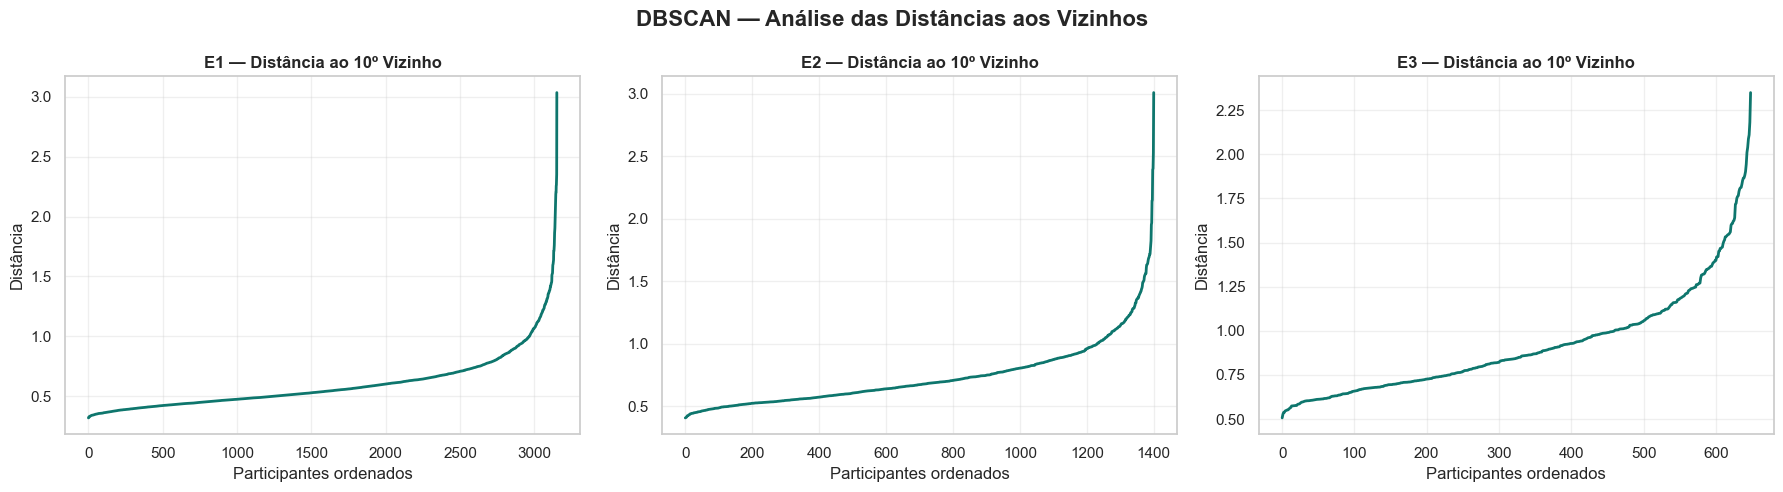

In [19]:

from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt
import joblib

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

min_samples_inicial = 10

for ax, (codigo, nome_estrato, arquivo_modelo) in zip(
    axes, estratos
):
    artefato = joblib.load(
        PASTA_MODELOS / f"{arquivo_modelo}_kmeans.joblib"
    )

    scaler = artefato["scaler"]
    variaveis = artefato["features"]

    dados = df[
        df["estrato_hba1c"] == nome_estrato
    ]

    X_scaled = scaler.transform(dados[variaveis])

    vizinhos = NearestNeighbors(
        n_neighbors=min_samples_inicial,
        metric="euclidean"
    )

    vizinhos.fit(X_scaled)

    distancias, _ = vizinhos.kneighbors(X_scaled)

    # Distância ao 10º vizinho, incluindo o próprio ponto
    distancias_k = np.sort(
        distancias[:, -1]
    )

    ax.plot(
        distancias_k,
        color="#0E766D",
        linewidth=2
    )

    ax.set_title(
        f"{codigo} — Distância ao 10º Vizinho",
        fontweight="bold"
    )

    ax.set_xlabel("Participantes ordenados")
    ax.set_ylabel("Distância")
    ax.grid(alpha=0.3)

fig.suptitle(
    "DBSCAN — Análise das Distâncias aos Vizinhos",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



### Interpretação das Distâncias aos Vizinhos

Os gráficos de distância ao décimo vizinho apresentaram
crescimento gradual, seguido de aumento mais acentuado
nas regiões finais das curvas.

Esse comportamento sugere a presença de observações
localizadas em regiões de menor densidade no espaço
das variáveis cardiometabólicas.

As curvas dos três estratos apresentaram diferenças,
indicando que a escolha do parâmetro eps deve ser
avaliada separadamente para cada conjunto de dados.

Como não foi identificado um ponto de inflexão
inequívoco, foram definidas faixas exploratórias
de eps para comparação de diferentes configurações
do DBSCAN.

A seleção dos parâmetros considerará o número de
clusters identificados, a proporção de observações
classificadas como ruído e a qualidade da separação
dos agrupamentos.



## 5.2. Avaliação dos Parâmetros do DBSCAN

Foram testadas diferentes combinações dos parâmetros
eps e min_samples, separadamente em cada estrato
de HbA1c.

O parâmetro eps determina o raio da vizinhança,
enquanto min_samples estabelece o número mínimo
de observações necessário para caracterizar uma
região como suficientemente densa.

As configurações foram avaliadas considerando o
número de clusters, a proporção de participantes
classificados como ruído e o Silhouette Score
dos participantes agrupados.

O Silhouette Score não foi calculado para
configurações com menos de dois clusters válidos.


In [21]:

from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import numpy as np
import pandas as pd
import joblib

# Faixas exploratórias por estrato
eps_por_estrato = {
    "E1": np.arange(0.6, 1.21, 0.1),
    "E2": np.arange(0.7, 1.31, 0.1),
    "E3": np.arange(0.8, 1.61, 0.1)
}

min_samples_opcoes = [5, 10, 15, 20]

resultados_dbscan = []

for codigo, nome_estrato, arquivo_modelo in estratos:

    artefato = joblib.load(
        PASTA_MODELOS / f"{arquivo_modelo}_kmeans.joblib"
    )

    scaler = artefato["scaler"]
    variaveis = artefato["features"]

    dados = df[
        df["estrato_hba1c"] == nome_estrato
    ]

    X_scaled = scaler.transform(dados[variaveis])
    total = len(dados)

    for eps in eps_por_estrato[codigo]:
        for min_samples in min_samples_opcoes:

            modelo_dbscan = DBSCAN(
                eps=float(eps),
                min_samples=min_samples
            )

            labels = modelo_dbscan.fit_predict(X_scaled)

            mascara_validos = labels != -1

            n_validos = int(mascara_validos.sum())
            n_ruido = total - n_validos

            clusters_validos = np.unique(
                labels[mascara_validos]
            )

            n_clusters = len(clusters_validos)

            percentual_ruido = (
                n_ruido / total * 100
            )

            silhouette = np.nan

            # Silhouette apenas para configurações válidas
            if 2 <= n_clusters < n_validos:
                silhouette = silhouette_score(
                    X_scaled[mascara_validos],
                    labels[mascara_validos]
                )

            resultados_dbscan.append({
                "estrato": codigo,
                "eps": round(float(eps), 2),
                "min_samples": min_samples,
                "n_clusters": n_clusters,
                "n_agrupados": n_validos,
                "percentual_ruido": percentual_ruido,
                "silhouette": silhouette
            })

resultados_dbscan = pd.DataFrame(
    resultados_dbscan
)

print("Total de configurações testadas:", len(resultados_dbscan))

display(
    resultados_dbscan.groupby("estrato").agg(
        configuracoes=("eps", "count"),
        configuracoes_com_silhouette=("silhouette", "count"),
        menor_ruido=("percentual_ruido", "min"),
        maior_ruido=("percentual_ruido", "max")
    ).round(2)
)


Total de configurações testadas: 92


,configuracoes,configuracoes_com_silhouette,menor_ruido,maior_ruido
estrato,,,,
E1,28,3,0.63,31.85
E2,28,1,0.86,36.33
E3,36,1,0.15,52.08


In [22]:

configuracoes_validas = resultados_dbscan[
    (resultados_dbscan["n_clusters"] >= 2)
    & (resultados_dbscan["percentual_ruido"] <= 30)
    & (resultados_dbscan["silhouette"].notna())
].copy()

melhores_configuracoes = (
    configuracoes_validas
    .sort_values(
        ["estrato", "silhouette"],
        ascending=[True, False]
    )
    .groupby("estrato")
    .head(5)
)

display(
    melhores_configuracoes[
        [
            "estrato",
            "eps",
            "min_samples",
            "n_clusters",
            "n_agrupados",
            "percentual_ruido",
            "silhouette"
        ]
    ].round(3)
)


,estrato,eps,min_samples,n_clusters,n_agrupados,percentual_ruido,silhouette
12,E1,0.9,5,2,3071,2.570,0.390
4,E1,0.7,5,2,2925,7.202,0.318
8,E1,0.8,5,2,3014,4.378,0.296
40,E2,1.0,5,2,1359,2.998,0.359
65,E3,1.0,10,2,579,10.786,0.273



## 5.3. Distribuição dos Clusters Identificados pelo DBSCAN

Foram selecionadas configurações exploratórias do DBSCAN
que apresentaram dois agrupamentos e valores de
Silhouette relativamente elevados.

Nesta etapa, será analisada a distribuição dos
participantes entre os clusters e o grupo de ruído.

Essa verificação é necessária porque valores elevados
de Silhouette não garantem que os agrupamentos tenham
tamanhos equilibrados ou sejam adequados ao objetivo
de caracterização cardiometabólica.


In [23]:
# Configurações selecionadas para inspeção
parametros_dbscan = {
    "E1": {"eps": 0.9, "min_samples": 5},
    "E2": {"eps": 1.0, "min_samples": 5},
    "E3": {"eps": 1.0, "min_samples": 10}
}

distribuicoes_dbscan = []
resultados_labels_dbscan = {}

for codigo, nome_estrato, arquivo_modelo in estratos:

    artefato = joblib.load(
        PASTA_MODELOS / f"{arquivo_modelo}_kmeans.joblib"
    )

    scaler = artefato["scaler"]
    variaveis = artefato["features"]

    dados = df[
        df["estrato_hba1c"] == nome_estrato
    ].copy()

    X_scaled = scaler.transform(dados[variaveis])

    parametros = parametros_dbscan[codigo]

    dbscan = DBSCAN(
        eps=parametros["eps"],
        min_samples=parametros["min_samples"]
    )

    dados["cluster_dbscan"] = dbscan.fit_predict(
        X_scaled
    )

    resultados_labels_dbscan[codigo] = dados

    contagem = (
        dados["cluster_dbscan"]
        .value_counts()
        .sort_index()
    )

    for cluster, quantidade in contagem.items():

        distribuicoes_dbscan.append({
            "estrato": codigo,
            "cluster": int(cluster),
            "participantes": int(quantidade),
            "percentual": (
                quantidade / len(dados) * 100
            )
        })

distribuicao_dbscan = pd.DataFrame(
    distribuicoes_dbscan
)

display(
    distribuicao_dbscan.round(2)
)


,estrato,cluster,participantes,percentual
0,E1,-1,81,2.57
1,E1,0,3067,97.30
2,E1,1,4,0.13
3,E2,-1,42,3.00
4,E2,0,1355,96.72
5,E2,1,4,0.29
6,E3,-1,70,10.79
7,E3,0,574,88.44
8,E3,1,5,0.77


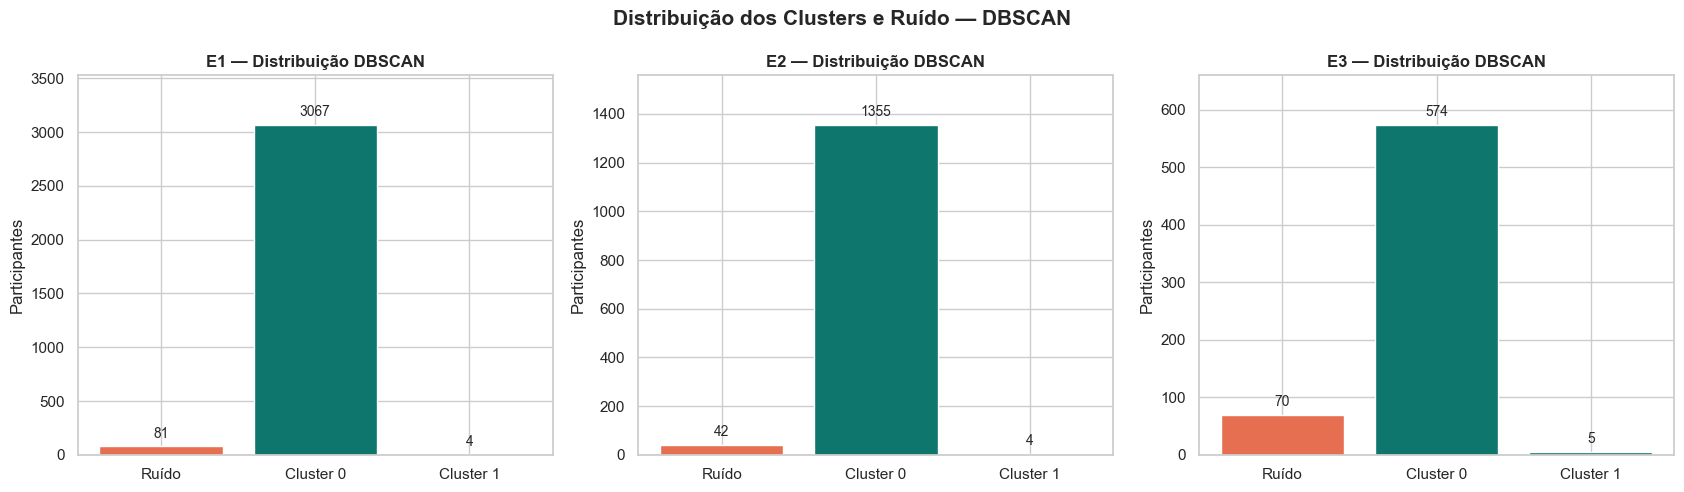

In [24]:

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (codigo, _, _) in zip(axes, estratos):

    dados = distribuicao_dbscan[
        distribuicao_dbscan["estrato"] == codigo
    ]

    rotulos = [
        "Ruído" if cluster == -1 else f"Cluster {cluster}"
        for cluster in dados["cluster"]
    ]

    cores = [
        "#E76F51" if cluster == -1 else "#0E766D"
        for cluster in dados["cluster"]
    ]

    barras = ax.bar(
        rotulos,
        dados["participantes"],
        color=cores
    )

    ax.bar_label(
        barras,
        padding=4,
        fontsize=10
    )

    ax.set_title(
        f"{codigo} — Distribuição DBSCAN",
        fontweight="bold"
    )

    ax.set_ylabel("Participantes")
    ax.set_ylim(
        0,
        dados["participantes"].max() * 1.15
    )

fig.suptitle(
    "Distribuição dos Clusters e Ruído — DBSCAN",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



### 5.3.1. Interpretação dos Agrupamentos do DBSCAN

A avaliação das configurações selecionadas do DBSCAN
identificou dois clusters em cada estrato de HbA1c.

Entretanto, observou-se uma distribuição fortemente
desigual dos participantes entre os agrupamentos.

No Estrato 1, o cluster principal reuniu 3.067
participantes (97,30%), enquanto o segundo cluster
apresentou apenas 4 participantes (0,13%).
Outros 81 participantes (2,57%) foram classificados
como ruído.

No Estrato 2, o cluster principal reuniu 1.355
participantes (96,72%), enquanto o segundo cluster
apresentou 4 participantes (0,29%).
O algoritmo classificou 42 participantes (3,00%)
como ruído.

No Estrato 3, o cluster principal reuniu 574
participantes (88,44%), enquanto o segundo cluster
apresentou apenas 5 participantes (0,77%).
Outros 70 participantes (10,79%) foram classificados
como ruído.

Embora essas configurações tenham apresentado
Silhouette Scores superiores aos obtidos pelo
K-Means, os resultados indicaram predomínio de
um único agrupamento em cada estrato.

Os valores de Silhouette do DBSCAN foram calculados
excluindo as observações classificadas como ruído,
o que limita sua comparação direta com o K-Means.

A presença de clusters secundários extremamente
pequenos também restringe a utilidade da solução
para a caracterização de subperfis cardiometabólicos.

Dessa forma, nas configurações avaliadas, o DBSCAN
não apresentou uma segmentação suficientemente
diversificada para substituir o K-Means como
método principal do estudo.



## 5.4. Visualização dos Agrupamentos do DBSCAN com PCA

Foi aplicada a Análise de Componentes Principais
(PCA) para representar os agrupamentos produzidos
pelo DBSCAN em duas dimensões.

O PCA foi ajustado separadamente em cada estrato,
utilizando as cinco variáveis cardiometabólicas
transformadas pelo RobustScaler.

Os participantes classificados como ruído foram
destacados separadamente dos clusters identificados.

A visualização tem caráter exploratório, pois
as duas primeiras componentes não preservam
necessariamente toda a estrutura de distâncias
do espaço original.


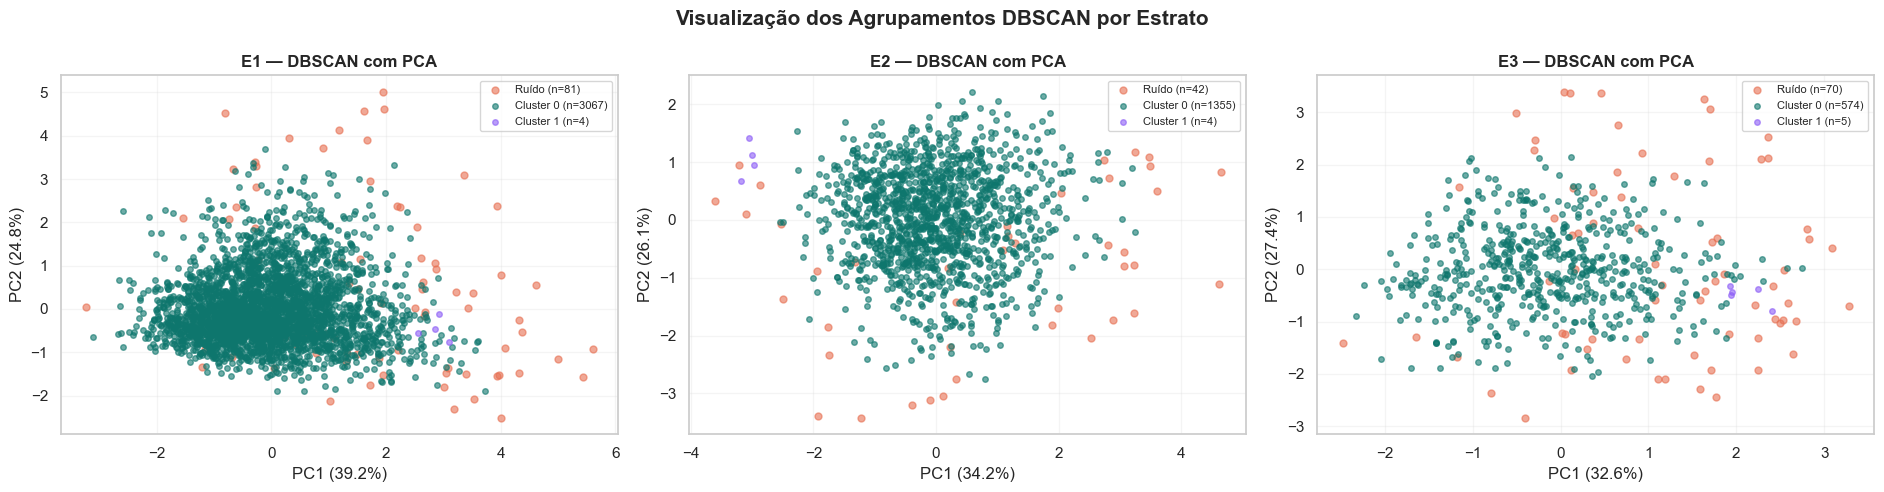

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

cores_dbscan = {
    -1: "#E76F51",  # Ruído
     0: "#0E766D",  # Cluster principal
     1: "#8B5CF6"   # Cluster secundário
}

for ax, (codigo, nome_estrato, arquivo_modelo) in zip(
    axes, estratos
):

    dados = resultados_labels_dbscan[codigo]

    artefato = joblib.load(
        PASTA_MODELOS / f"{arquivo_modelo}_kmeans.joblib"
    )

    scaler = artefato["scaler"]
    variaveis = artefato["features"]

    X_scaled = scaler.transform(dados[variaveis])

    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X_scaled)

    labels = dados["cluster_dbscan"].to_numpy()

    for cluster in sorted(np.unique(labels)):

        mascara = labels == cluster

        nome = (
            "Ruído" if cluster == -1
            else f"Cluster {cluster}"
        )

        ax.scatter(
            X_pca[mascara, 0],
            X_pca[mascara, 1],
            s=16 if cluster != -1 else 25,
            alpha=0.6,
            color=cores_dbscan.get(cluster, "#888888"),
            label=f"{nome} (n={mascara.sum()})"
        )

    ax.set_title(
        f"{codigo} — DBSCAN com PCA",
        fontweight="bold"
    )

    ax.set_xlabel(
        f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)"
    )

    ax.set_ylabel(
        f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)"
    )

    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)

fig.suptitle(
    "Visualização dos Agrupamentos DBSCAN por Estrato",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



### 5.4.1. Interpretação da Visualização PCA do DBSCAN

A projeção dos agrupamentos do DBSCAN nas duas
primeiras componentes principais evidenciou o
predomínio de um cluster central em cada estrato
de HbA1c.

No Estrato 1, o agrupamento principal reuniu
3.067 participantes, enquanto o segundo cluster
continha apenas 4 observações.

No Estrato 2, foram identificados 1.355 participantes
no agrupamento principal e apenas 4 no secundário.

No Estrato 3, o agrupamento principal reuniu
574 participantes, enquanto o secundário
apresentou 5 observações.

As observações classificadas como ruído apareceram
principalmente em regiões periféricas das projeções,
embora também tenham ocorrido próximas das regiões
centrais.

Esses resultados são compatíveis com a identificação
de uma região principal de maior densidade e pequenos
agrupamentos secundários.

Embora o DBSCAN tenha apresentado Silhouette Scores
superiores aos do K-Means nas configurações selecionadas,
a distribuição extremamente desigual dos participantes
reduziu a utilidade dos agrupamentos para o objetivo
de caracterização de subperfis cardiometabólicos.

Além disso, o Silhouette do DBSCAN foi calculado
sem as observações classificadas como ruído, o que
limita a comparação direta entre os algoritmos.

A projeção PCA possui finalidade exploratória e
não preserva integralmente as distâncias do espaço
original de cinco dimensões.



## 5.5. Conclusão do Experimento Comparativo

A comparação entre K-Means e DBSCAN demonstrou
diferenças relevantes na estrutura dos agrupamentos
identificados nos três estratos de HbA1c.

O K-Means permitiu identificar dez subperfis
cardiometabólicos, com distribuição de participantes
que possibilitou sua caracterização por idade, IMC,
pressão arterial e colesterol total.

Por outro lado, o DBSCAN, nas configurações avaliadas,
identificou predominantemente um único agrupamento
de grande dimensão em cada estrato, acompanhado de
clusters secundários contendo apenas quatro ou
cinco participantes.

Embora determinadas configurações do DBSCAN tenham
apresentado coeficientes de Silhouette superiores,
essa vantagem não se traduziu em agrupamentos
adequados ao objetivo descritivo do estudo.

A análise demonstrou a importância de considerar,
além das métricas de separação, a distribuição dos
participantes, a proporção de ruído e a
interpretabilidade dos agrupamentos.

Dessa forma, o K-Means foi mantido como algoritmo
principal do HealthSync, enquanto o DBSCAN foi
utilizado como método comparativo exploratório.

Essa escolha não implica superioridade geral do
K-Means, mas reflete sua maior adequação ao objetivo
e às configurações examinadas neste estudo.


In [26]:

features = [
    "idade",
    "imc",
    "pressao_sistolica",
    "pressao_diastolica",
    "colesterol_total"
]

for codigo in ["E1", "E2", "E3"]:

    dados = resultados_labels_dbscan[codigo]

    grupo_pequeno = dados[
        dados["cluster_dbscan"] == 1
    ]

    print(f"\n{codigo} — Cluster secundário")
    print(f"Participantes: {len(grupo_pequeno)}")

    display(
        grupo_pequeno[features].round(1)
    )

    print("Medianas do cluster secundário:")
    display(
        grupo_pequeno[features].median().round(1)
    )



E1 — Cluster secundário
Participantes: 4


,idade,imc,pressao_sistolica,pressao_diastolica,colesterol_total
543,56.0,28.3,178.0,88.0,161.0
1044,76.0,27.2,185.0,94.3,135.0
1786,77.0,32.1,176.3,93.0,146.0
1836,73.0,29.9,178.7,90.3,161.0


Medianas do cluster secundário:


idade                  74.5
imc                    29.1
pressao_sistolica     178.4
pressao_diastolica     91.6
colesterol_total      153.5
dtype: float64


E2 — Cluster secundário
Participantes: 4


...

idade                  80.0
imc                    24.6
pressao_sistolica      93.5
pressao_diastolica     38.8
colesterol_total      140.0
dtype: float64


E3 — Cluster secundário
Participantes: 5


,idade,imc,pressao_sistolica,pressao_diastolica,colesterol_total
4682,28.0,33.9,130.7,95.3,173.0
4717,36.0,45.7,132.7,94.0,179.0
4828,32.0,36.8,126.7,95.0,186.0
4979,31.0,44.4,137.0,94.3,187.0
5152,32.0,44.4,125.0,97.0,208.0


Medianas do cluster secundário:


idade                  32.0
imc                    44.4
pressao_sistolica     130.7
pressao_diastolica     95.0
colesterol_total      186.0
dtype: float64


### 5.4.2. Caracterização dos Clusters Secundários do DBSCAN

A análise dos clusters secundários identificados pelo
DBSCAN revelou pequenos agrupamentos com características
cardiometabólicas relativamente incomuns.

No Estrato 1, o cluster secundário, composto por quatro
participantes, apresentou mediana de idade de 74,5 anos
e pressão sistólica de 178,4 mmHg, destacando-se pelos
valores elevados de pressão sistólica.

No Estrato 2, o agrupamento secundário reuniu quatro
participantes com mediana de idade de 80 anos e
pressões sistólica e diastólica de 93,5 mmHg e
38,8 mmHg, respectivamente. Esses valores foram
consideravelmente inferiores às medianas observadas
nos perfis principais do estrato.

No Estrato 3, o cluster secundário apresentou cinco
participantes, com mediana de idade de 32 anos,
IMC de 44,4 kg/m² e pressão diastólica de
95,0 mmHg.

Esses resultados sugerem que o DBSCAN identificou
pequenos conjuntos com combinações específicas de
indicadores cardiometabólicos, em vez de produzir
uma segmentação ampla da amostra.

Entretanto, o tamanho reduzido desses agrupamentos
limita sua interpretação e não permite estabelecer
categorias clínicas ou conclusões populacionais.

Os resultados reforçam a escolha do K-Means como
algoritmo principal para a caracterização descritiva
dos participantes, considerando as configurações
avaliadas neste estudo.



## 5.5. Comparação Final entre K-Means e DBSCAN

Os resultados dos algoritmos foram comparados considerando
o número de clusters, o coeficiente de Silhouette,
a proporção de participantes classificados como ruído
e a distribuição dos participantes entre os agrupamentos.

A comparação busca avaliar a adequação dos algoritmos
ao objetivo de identificar subperfis cardiometabólicos
descritivos dentro de cada estrato de HbA1c.

Os valores de Silhouette do DBSCAN foram calculados
somente entre participantes não classificados como ruído.
Portanto, não são diretamente equivalentes aos resultados
do K-Means, que considerou todos os participantes.


In [27]:

import pandas as pd

# Resultados previamente obtidos com o K-Means
metricas_kmeans = {
    "E1": {"clusters": 2, "silhouette": 0.2382},
    "E2": {"clusters": 6, "silhouette": 0.1920},
    "E3": {"clusters": 2, "silhouette": 0.2119}
}

# Configurações selecionadas do DBSCAN
parametros_finais = {
    "E1": {"eps": 0.9, "min_samples": 5},
    "E2": {"eps": 1.0, "min_samples": 5},
    "E3": {"eps": 1.0, "min_samples": 10}
}

linhas_comparacao = []

for codigo in ["E1", "E2", "E3"]:

    dados_estrato = distribuicao_dbscan[
        distribuicao_dbscan["estrato"] == codigo
    ]

    total = int(dados_estrato["participantes"].sum())

    clusters_dbscan = dados_estrato[
        dados_estrato["cluster"] != -1
    ]

    ruido = dados_estrato[
        dados_estrato["cluster"] == -1
    ]["participantes"].sum()

    # Recuperar o Silhouette da configuração escolhida
    parametros = parametros_finais[codigo]

    resultado_dbscan = resultados_dbscan[
        (resultados_dbscan["estrato"] == codigo)
        & (
            resultados_dbscan["eps"]
            == parametros["eps"]
        )
        & (
            resultados_dbscan["min_samples"]
            == parametros["min_samples"]
        )
    ]

    silhouette_dbscan = (
        resultado_dbscan["silhouette"].iloc[0]
    )

    linhas_comparacao.append({
        "Estrato": codigo,
        "Algoritmo": "K-Means",
        "Clusters": metricas_kmeans[codigo]["clusters"],
        "Silhouette": metricas_kmeans[codigo]["silhouette"],
        "Ruído (%)": 0.0,
        "Menor cluster": (
            {
                "E1": 1218,
                "E2": 154,
                "E3": 250
            }[codigo]
        ),
        "Cobertura (%)": 100.0
    })

    linhas_comparacao.append({
        "Estrato": codigo,
        "Algoritmo": "DBSCAN",
        "Clusters": len(clusters_dbscan),
        "Silhouette": silhouette_dbscan,
        "Ruído (%)": ruido / total * 100,
        "Menor cluster": int(
            clusters_dbscan["participantes"].min()
        ),
        "Cobertura (%)": (total - ruido) / total * 100
    })

comparacao_final = pd.DataFrame(linhas_comparacao)

display(comparacao_final.round(3))


,Estrato,Algoritmo,Clusters,Silhouette,Ruído (%),Menor cluster,Cobertura (%)
0,E1,K-Means,2,0.238,0.000,1218,100.000
1,E1,DBSCAN,2,0.390,2.570,4,97.430
2,E2,K-Means,6,0.192,0.000,154,100.000
3,E2,DBSCAN,2,0.359,2.998,4,97.002
4,E3,K-Means,2,0.212,0.000,250,100.000
5,E3,DBSCAN,2,0.273,10.786,5,89.214


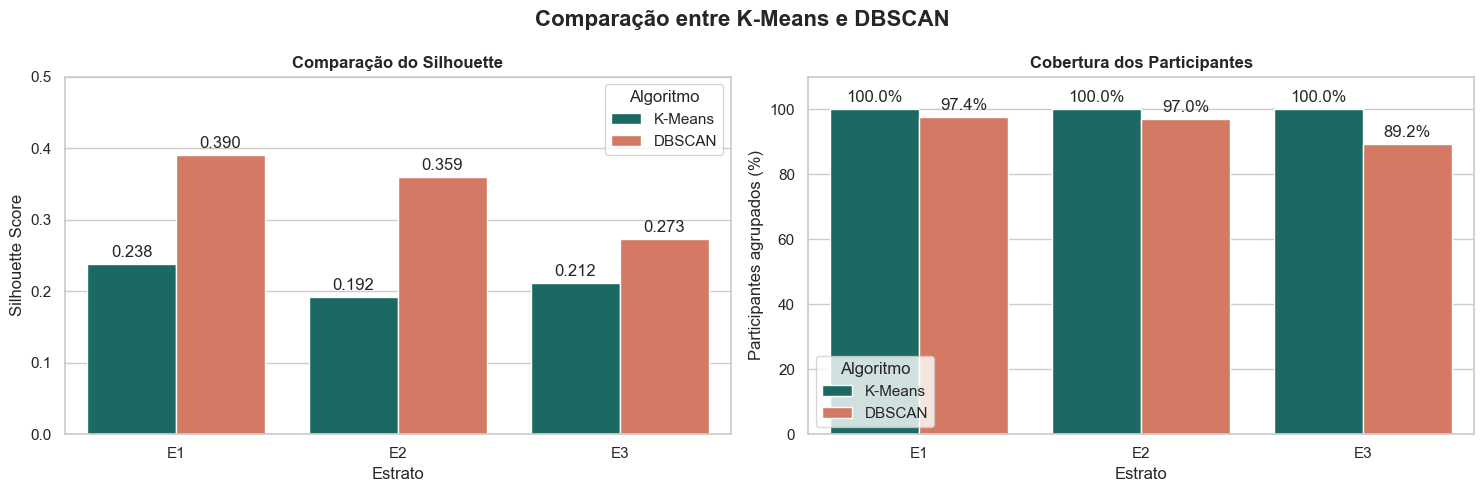

In [28]:

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

cores = {
    "K-Means": "#0E766D",
    "DBSCAN": "#E76F51"
}

sns.barplot(
    data=comparacao_final,
    x="Estrato",
    y="Silhouette",
    hue="Algoritmo",
    palette=cores,
    errorbar=None,
    ax=axes[0]
)

axes[0].set_title(
    "Comparação do Silhouette",
    fontweight="bold"
)
axes[0].set_ylabel("Silhouette Score")
axes[0].set_xlabel("Estrato")
axes[0].set_ylim(0, 0.5)

for container in axes[0].containers:
    axes[0].bar_label(
        container,
        fmt="%.3f",
        padding=3
    )

sns.barplot(
    data=comparacao_final,
    x="Estrato",
    y="Cobertura (%)",
    hue="Algoritmo",
    palette=cores,
    errorbar=None,
    ax=axes[1]
)

axes[1].set_title(
    "Cobertura dos Participantes",
    fontweight="bold"
)
axes[1].set_ylabel("Participantes agrupados (%)")
axes[1].set_xlabel("Estrato")
axes[1].set_ylim(0, 110)

for container in axes[1].containers:
    axes[1].bar_label(
        container,
        fmt="%.1f%%",
        padding=3
    )

fig.suptitle(
    "Comparação entre K-Means e DBSCAN",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



### 5.5.1. Discussão Comparativa

A comparação experimental demonstrou que os algoritmos
K-Means e DBSCAN produziram estruturas de agrupamento
distintas nos três estratos de HbA1c.

O K-Means identificou dez subperfis cardiometabólicos,
distribuídos em dois clusters no Estrato 1, seis no
Estrato 2 e dois no Estrato 3.

Os agrupamentos do K-Means apresentaram tamanhos
suficientes para análises descritivas, embora os
coeficientes de Silhouette tenham indicado separação
limitada entre os grupos.

O DBSCAN apresentou valores de Silhouette superiores
nas configurações selecionadas. Entretanto, identificou
predominantemente um único cluster de grande dimensão
em cada estrato, acompanhado de agrupamentos secundários
contendo apenas quatro ou cinco participantes.

Além disso, o DBSCAN classificou parte dos participantes
como ruído, enquanto o K-Means atribuiu todos os
participantes a algum agrupamento.

É importante destacar que os valores de Silhouette
dos dois algoritmos foram calculados sobre conjuntos
diferentes de participantes, limitando sua
comparabilidade direta.

Considerando o objetivo de identificar subperfis
cardiometabólicos descritivos e interpretáveis,
o K-Means apresentou maior adequação nas configurações
avaliadas.

O DBSCAN demonstrou potencial para identificar pequenos
conjuntos de observações com características
cardiometabólicas incomuns, podendo ser investigado
futuramente em análises exploratórias específicas.

Portanto, o K-Means foi mantido como algoritmo
principal do estudo, sem que isso implique
superioridade geral sobre o DBSCAN.


## 6. Discussão Geral dos Resultados

O presente estudo investigou a identificação de subperfis cardiometabólicos por meio de técnicas de aprendizado de máquina não supervisionado, utilizando dados de 5.202 participantes do NHANES 2021–2023.

Os participantes foram divididos em três estratos segundo os valores de hemoglobina glicada (HbA1c): inferior a 5,7%, entre 5,7% e 6,5%, e igual ou superior a 6,5%. Essa divisão permitiu investigar diferenças nos indicadores cardiometabólicos dentro de cada faixa glicêmica.

Para a formação dos agrupamentos, foram consideradas cinco variáveis: idade, índice de massa corporal (IMC), pressão arterial sistólica, pressão arterial diastólica e colesterol total.

### 6.1. Identificação dos subperfis cardiometabólicos

A aplicação do algoritmo K-Means resultou na identificação de dez subperfis cardiometabólicos, distribuídos em dois agrupamentos no primeiro estrato, seis no segundo e dois no terceiro.

No primeiro estrato, os agrupamentos apresentaram diferenças principalmente relacionadas à idade, ao IMC, à pressão arterial e ao colesterol total.

No segundo estrato, foi observada maior diversidade de padrões, incluindo agrupamentos caracterizados por pressão arterial relativamente elevada, IMC elevado, colesterol total elevado e diferenças associadas à idade.

No terceiro estrato, os dois agrupamentos apresentaram diferenças principalmente relacionadas à idade, ao IMC, à pressão diastólica e ao colesterol total.

Esses resultados demonstram que participantes pertencentes à mesma faixa de HbA1c podem apresentar diferentes combinações de características cardiometabólicas.

Entretanto, os agrupamentos representam padrões estatísticos descritivos, não devendo ser interpretados como diagnósticos ou categorias clínicas validadas.

### 6.2. Qualidade e estabilidade dos agrupamentos

Os valores de Silhouette obtidos pelo K-Means foram de 0,2382, 0,1920 e 0,2119 para os três estratos, respectivamente.

Esses resultados indicam separação limitada entre os agrupamentos, sugerindo a existência de sobreposição entre os perfis identificados.

Apesar disso, as análises de estabilidade apresentaram valores médios de Adjusted Rand Index (ARI) de aproximadamente 0,932 no primeiro estrato, 0,872 no segundo e 0,872 no terceiro, indicando concordância relativamente elevada com as partições de referência nos procedimentos de reamostragem realizados.

A estabilidade observada não elimina a sobreposição entre os grupos nem constitui validação clínica dos perfis.

### 6.3. Comparação entre K-Means e DBSCAN

Como experimento complementar, foi aplicado o algoritmo DBSCAN, utilizando as mesmas variáveis cardiometabólicas e a mesma estratégia de padronização.

Embora determinadas configurações do DBSCAN tenham apresentado valores de Silhouette superiores aos do K-Means, os agrupamentos identificados mostraram distribuição extremamente desigual.

Nos três estratos, o DBSCAN identificou predominantemente um único cluster de grande dimensão, acompanhado de um agrupamento secundário contendo apenas quatro ou cinco participantes.

A análise desses pequenos agrupamentos revelou combinações específicas de indicadores cardiometabólicos, incluindo pressão sistólica elevada, pressão diastólica muito baixa e IMC elevado.

Entretanto, o tamanho reduzido desses grupos restringe sua interpretação como subperfis representativos da amostra.

Considerando a finalidade descritiva do estudo, o K-Means demonstrou maior adequação nas configurações avaliadas, por permitir a caracterização de agrupamentos com tamanhos mais substanciais e atribuir todos os participantes a algum perfil.

### 6.4. Relação com atividade física e comportamento sedentário

As variáveis relacionadas à atividade física moderada, atividade física vigorosa e tempo sedentário não participaram da formação dos clusters finais.

Elas foram utilizadas posteriormente para caracterizar os comportamentos observados nos diferentes perfis cardiometabólicos.

As análises descritivas identificaram diferenças entre os agrupamentos quanto à proporção de participantes com atividade física registrada e à duração das atividades.

Entretanto, essas diferenças não permitem estabelecer relações causais entre atividade física, sedentarismo e os indicadores cardiometabólicos, considerando a natureza observacional e transversal dos dados.

### 6.5. Implicações para o HealthSync

Os resultados demonstram a possibilidade de utilizar técnicas de aprendizado de máquina não supervisionado para identificar padrões descritivos em dados cardiometabólicos.

No contexto do HealthSync, os modelos desenvolvidos poderão subsidiar funcionalidades de visualização e comparação de indicadores de saúde, permitindo apresentar ao usuário características de perfis semelhantes aos identificados na amostra estudada.

Contudo, a aplicação dos modelos em usuários reais exige validação adicional, especialmente em populações diferentes daquela utilizada no treinamento.

Os agrupamentos não devem ser empregados isoladamente para diagnóstico, classificação de risco clínico ou recomendação de tratamentos.


# 7. Limitações do Estudo

Apesar dos resultados obtidos, algumas limitações
metodológicas devem ser consideradas.

### 7.1. Representatividade da amostra

O estudo utilizou dados do NHANES 2021–2023,
referentes à população dos Estados Unidos.

Embora o NHANES seja uma pesquisa populacional,
a amostra utilizada neste experimento foi restrita
a 5.202 participantes com dados completos nas
variáveis selecionadas.

Além disso, não foram incorporados os pesos amostrais,
estratos e unidades primárias de amostragem do desenho
complexo do NHANES. Portanto, os resultados não devem
ser interpretados como estimativas representativas
da população norte-americana.

Também não é possível generalizar diretamente os
agrupamentos identificados para a população brasileira,
que constitui um possível público do HealthSync.

### 7.2. Natureza transversal dos dados

Os dados analisados possuem natureza transversal,
representando observações coletadas em determinado
período.

Consequentemente, os resultados permitem identificar
associações e padrões descritivos, mas não estabelecer
relações de causalidade entre indicadores
cardiometabólicos e hábitos comportamentais.

### 7.3. Seleção das variáveis

A clusterização final utilizou cinco variáveis:
idade, IMC, pressão sistólica, pressão diastólica
e colesterol total.

Outros fatores potencialmente relevantes, como
uso de medicamentos, histórico de doenças,
alimentação e características sociodemográficas,
não foram incorporados à formação dos clusters.

As variáveis de atividade física e comportamento
sedentário foram utilizadas apenas para
caracterização posterior dos perfis.

Assim, os agrupamentos representam padrões
relacionados exclusivamente às variáveis
selecionadas para o modelo.

### 7.4. Separação dos agrupamentos

Os coeficientes de Silhouette do K-Means variaram
entre aproximadamente 0,19 e 0,24, indicando
separação relativamente limitada entre os clusters.

Embora as análises de estabilidade tenham apresentado
concordância relativamente elevada com as partições
de referência, isso não elimina a sobreposição
entre os perfis identificados.

Dessa forma, os clusters devem ser interpretados
como agrupamentos estatísticos exploratórios,
e não como categorias clínicas claramente delimitadas.

### 7.5. Ausência de validação clínica e externa

Os perfis foram caracterizados com base nas
distribuições observadas das variáveis
cardiometabólicas.

Não foi realizada validação clínica independente
para verificar se esses agrupamentos correspondem
a condições de saúde específicas.

Também não foi conduzida validação externa em
outra base de dados ou população.

Consequentemente, os resultados não devem ser
utilizados isoladamente para diagnóstico,
previsão de doenças ou classificação de risco clínico.

### 7.6. Limitações do DBSCAN

O experimento comparativo com DBSCAN foi conduzido
sobre faixas exploratórias dos parâmetros eps e
min_samples.

Nas configurações selecionadas, o algoritmo
identificou predominantemente um grande cluster
por estrato, acompanhado de pequenos agrupamentos
secundários.

Esses resultados não demonstram que o DBSCAN seja
inadequado para todas as possíveis configurações,
métricas de distância ou estratégias de
pré-processamento.

A comparação realizada está limitada às condições
experimentais investigadas.


# 8. Conclusão

O presente estudo teve como objetivo identificar subperfis cardiometabólicos descritivos em participantes do NHANES 2021–2023, utilizando técnicas de aprendizado de máquina não supervisionado.

A análise foi realizada com 5.202 participantes, distribuídos em três estratos de hemoglobina glicada (HbA1c), e considerou cinco indicadores cardiometabólicos: idade, índice de massa corporal, pressão arterial sistólica, pressão arterial diastólica e colesterol total.

A aplicação do algoritmo K-Means permitiu identificar dez subperfis cardiometabólicos, distribuídos em dois agrupamentos no primeiro estrato, seis no segundo e dois no terceiro. Esses agrupamentos apresentaram diferentes combinações de características, demonstrando a heterogeneidade cardiometabólica existente entre participantes pertencentes à mesma faixa de HbA1c.

A avaliação dos modelos revelou coeficientes de Silhouette relativamente modestos, indicando sobreposição entre os agrupamentos. Entretanto, os experimentos de estabilidade apresentaram concordância relativamente elevada com as partições de referência, contribuindo para a análise da consistência dos resultados.

Como abordagem complementar, foi avaliado o algoritmo DBSCAN. Embora determinadas configurações tenham apresentado coeficientes de Silhouette superiores, os agrupamentos resultantes foram fortemente desbalanceados, com predomínio de um único cluster e pequenos grupos secundários contendo apenas quatro ou cinco participantes.

Diante desses resultados, o K-Means foi mantido como método principal por apresentar maior adequação ao objetivo de caracterização descritiva dos participantes nas configurações avaliadas.

Adicionalmente, a análise das variáveis de atividade física e comportamento sedentário permitiu explorar diferenças comportamentais entre os perfis identificados, sem estabelecer relações causais.

Os resultados demonstram o potencial das técnicas de clusterização para apoiar análises exploratórias de dados cardiometabólicos e fundamentar futuras funcionalidades do HealthSync voltadas à visualização e compreensão de indicadores de saúde.

Entretanto, os perfis identificados não constituem diagnósticos, categorias clínicas validadas ou instrumentos de previsão de risco. Sua aplicação em usuários reais depende de avaliações adicionais, incluindo validação externa, análise de representatividade e investigação da utilidade dos agrupamentos em diferentes populações.

Conclui-se que o estudo atingiu seu objetivo exploratório ao identificar e caracterizar subperfis cardiometabólicos dentro dos três estratos de HbA1c, oferecendo uma base inicial para futuras investigações e para o desenvolvimento responsável de funcionalidades analíticas no HealthSync.